<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/30_QML_Defences_Against_ML_Attacks/QUBO_PoisoningDetection_He2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Q-Detection: finding poisoned training data with a QUBO-trained weight network, step by step

This notebook re-implements, runs and checks the method of

> Haoqi He, Xiaokai Lin, Jiancai Chen and Yan Xiao,
> "Q-Detection: A Quantum-Classical Hybrid Poisoning Attack Detection Method",
> Proceedings of the Thirty-Fourth International Joint Conference on Artificial Intelligence (IJCAI-25), pp. 5327-5335, 2025.
> https://doi.org/10.24963/ijcai.2025/593

The authors publish demonstration code on GitHub; this notebook is written from the method as the paper describes it and does not
copy that code. The paper's experiments use ResNet-18 on the full GTSRB data set, a GPU, and D-Wave / QBoson / Kaiwu annealer
*simulators* with up to 5000 qubits. None of that fits a free Colab CPU session, so this notebook runs a **scaled-down but complete**
version of the same experiment (smaller pool, smaller models, 16 x 16 images) and says, claim by claim, what it can and cannot confirm.

**What the notebook does.** (1) Downloads the real German Traffic Sign data set (GTSRB, 43 classes). (2) Poisons a pool of it with the
paper's three attacks: targeted label flipping, BadNets and a Narcissus-style clean-label backdoor. (3) Runs four baseline defences
(random, DCM, LossScan, autoencoder outlier) and a Meta-Sift-style classical bilevel method. (4) Builds the **Q-WAN**, a one-hidden-layer
Ising network whose training is written as a QUBO problem, solves that QUBO with simulated annealing and an exact solver (stand-ins for
the quantum annealer / coherent Ising machine of the paper) and trains the Q-WAN by equilibrium propagation inside the paper's
bilevel loop. (5) Compares the **Normalised Corruption Ratio (NCR)** of every method with the paper's Table 1, trains a new model on the
selected subset (paper Fig. 1) and re-checks the paper's speed-up arithmetic. (6) Adds a genuine gate-model part: the same QUBO solved by a
9-qubit QAOA circuit in Qiskit, drawn and verified.

**How to run.** Open in Colab (badge above), Runtime -> Run all on a **CPU** runtime; `FAST_MODE = True` (class demo) finishes in roughly
10 to 15 minutes on an idle machine (the stored run took 38 minutes on a heavily shared CPU). Set `FAST_MODE = False` in the configuration cell for the larger run (budgets are listed in the configuration cell; expect well over an hour). No GPU, no quantum hardware and no
account are needed; the data set is public, so the optional Hugging Face token (Colab Secrets -> `HF_TOKEN`) is not required.

**What you get at the end.** A table of NCR values next to the paper's, accuracy of a model trained on each defence's selected subset,
a study of the hidden-layer size (= number of qubits), a verdict ("reproduced" / "not reached here" / "cannot be checked") per claim, and
a critical reading of the paper.

## The paper in one page

**Problem.** A defender receives an image data set from outside (web scraping, crowdsourcing, a data marketplace). An attacker has
poisoned part of it. The defender wants to *sift out a clean subset* of fixed size (4,000 images in the paper) and train on that.
Three poisoning attacks are studied: **targeted label flipping** (labels change, images do not), **BadNets** (a pixel trigger is stamped
on images *and* their label is set to the target class) and **Narcissus** (a clean-label backdoor: only images already of the target
class get a small optimised trigger, labels stay correct).

**Decision.** For every training image: keep it in the clean subset, or not. The relaxed version gives each image a probability
$S(L_i;\psi)\in[0,1]$ of being clean, produced by a small *weight-assigning network* that sees the image's loss $L_i$.

**Method (Section 3).**
1. *Bilevel problem* (Eq. 4): find network parameters $\psi$ that maximise $\sum_i (1-S_i)L_i(\theta^*(\psi))$, i.e. the loss on the images that are *not*
   selected, where $\theta^*(\psi)$ minimises the weighted loss $\sum_i S_i L_i(\theta)$ of the *selected* images. The idea: a model fitted to clean images
   has high loss on poison, so the poison cannot hide among the low-loss data. This is the Meta-Sift formulation.
2. *Three stages per mini-batch*: Adversarial Filtering (update the weight network to maximise the loss on low-weight samples, Eq. 5),
   Selective Learning (a virtual copy of the model minimises the weighted loss, Eq. 6) and Actual-update (the real domain model takes the same step).
3. *Q-WAN* (Sections 3.2 and 3.3): the weight network is a **one-hidden-layer network of binary spins**. Its energy is an Ising model (Eq. 2),
   rewritten as a QUBO (Eq. 1 and 3) so that a quantum annealer, a coherent photonic Ising machine or QAOA on a gate-model computer can minimise it.
   Training is *equilibrium propagation*: solve the QUBO once with the output free (free state) and once with the output nudged toward its target (guided
   state, Eq. 7); the difference of spin correlations is the gradient (Eq. 10).
4. *Selection*: after training, the Q-WAN scores all images and the 4,000 with the highest weights form the clean subset.

**Data and models.** GTSRB (39,209 training and 12,630 test images, 43 classes), ResNet-18, PyTorch + CUDA for the classical part; Kaiwu SDK (600 qubits),
D-Wave SDK (5,000+ qubits) and Qiskit QAOA (30 qubits) *simulators* for the QUBO. Hidden-layer sizes of 20, 500 and 5000 neurons = 20, 500, 5000 qubits.
Poison ratios: label flipping and Narcissus 3, 5, 10, 20, 30 %; BadNets 1, 3, 5, 8, 10, 30 %.

**Metrics.** Corruption Ratio CR = poisoned images in the selected subset / subset size; **Normalised Corruption Ratio NCR = CR / CR of a random subset**
(Eq. 11 and 12). NCR = 0 % means a perfectly clean subset, NCR = 100 % is no better than random, NCR above 100 % is *worse* than random.

**Claims that can be checked here.**
- **C1** (Table 1) Q-Detection with 500 qubits reaches NCR = 0 % for label flipping at every ratio, and is mostly 0 % for the backdoors, but fails (NCR 110 to 366 %) on
  BadNets at 10 % and 30 % and on Narcissus at 30 %.
- **C2** (Table 1) With 5000 qubits Q-Detection reaches NCR = 0 % everywhere ("hidden layer size, i.e. qubit count, decides selection capability").
- **C3** (Sec. 4.2) With 20 neurons the training "fails" (QAOA: NCR = 929 %).
- **C4** (Table 1) Baselines: DCM is poor on label flipping (15 to 88 %) and BadNets, perfect on Narcissus; LossScan is bad on Narcissus (94 to 236 %) and mostly 0 % elsewhere;
  the autoencoder is bad on label flipping (77 to 118 %) and fine elsewhere; Meta-Sift is 0 % everywhere.
- **C5** (Fig. 1) A model trained on the Q-Detection subset reaches overall accuracy at least as high as one trained on the Meta-Sift subset (shown only as a bar chart, no numbers).
- **C6** (Sec. 4.4) The time estimate: 892 epochs, 3,568 device calls, 66.9 minutes simulated, about 2.17 minutes with a 1000x faster Ising machine, "over 20 %" faster than Meta-Sift's 3 minutes.
  This is arithmetic on reported numbers and is re-checked as such.

### What follows the paper and what had to be chosen

The paper is a short conference paper; many details needed to run it are not given. Every choice below is marked `# CHOICE:` where it appears in code.

| Item | Paper | This notebook |
|---|---|---|
| Data | GTSRB, 39,209 train / 12,630 test, full resolution | the public mirror `tanganke/gtsrb` (26,640 train / 12,630 test = the standard test set; the mirror's train split is smaller than the original 39,209); images resized to **16 x 16** RGB |
| Pool and subset | all training images, 4,000 selected (about 10 %) | a random pool of `N_POOL` (6,000 fast / 8,000 full) images; `K_SEL` = 15 % of the pool selected |
| Domain model | ResNet-18, GPU | **MLP** (pixels -> 192 -> 64 features -> linear head, 43 classes) for the detection loop, and the same MLP architecture, trained afresh for `FINAL_EPOCHS` epochs, for the new model of Fig. 1 (a small CNN did not do better on 16 x 16 images and costs 5x more CPU time) |
| Virtual model | a copy of the domain model | a copy of the **linear head** (so the hypergradient is analytic and exact for that head); the feature layers are updated in the actual-update stage |
| Weight-network input | the sample loss $L_i$ | $L_i$ as 16 clamped input spins (thermometer code of $\log L_i$) |
| Q-WAN | one hidden layer, binary neurons, 20 / 500 / 5000, Ising energy of Eq. 2 | exactly that: 16 input spins - H hidden spins - 1 output spin, $E=-s^\top J_1 h-(J_2\cdot h)\,o-b_h\cdot h-b_o o$; weight $S$ = probability that the output spin is +1 |
| QUBO solver | Kaiwu CIM simulator, D-Wave simulator, Qiskit QAOA (<= 30 qubits) | **simulated annealing** (block Gibbs, a classical stand-in for the annealer), an **exact Boltzmann solver** (the QUBO is a star graph) and a **9-qubit QAOA** circuit in Qiskit. No quantum annealer or photonic machine is used. |
| Training rule | equilibrium propagation, Eq. 10 | contrastive free-vs-guided update with the output spin clamped in the guided phase (the usual sign; the paper's Eq. 10 has an extra minus sign) |
| Target of the output spin | "guided excitation $\psi^*$ / $\theta^*(\psi)$" (Eq. 7), not specified further | the **sign of the hypergradient** $\partial F/\partial S_i$ of the outer objective $F=\sum_j(1-S_j)L_j(\theta')$ after one virtual step, split into two clusters by Otsu's rule, +1 = "increase this weight" |
| Attacks | Targeted Label-Flipping (Jha 2023), BadNets, Narcissus (Zeng 2023); target label 38 | label flipping: random non-target images relabelled 38; BadNets: 3 x 3 checkerboard patch + label 38; Narcissus-style: optimised 5 x 5 patch on target-class images only. Trigger sizes, the surrogate and the out-of-distribution data of Narcissus are not given in the paper |
| Poison ratio | fraction of the data set | fraction of the **pool** (label flipping, BadNets) or of the **target-class images** (Narcissus, because class 38 is only about 5 % of GTSRB) |
| Baselines | DCM, LossScan, autoencoder outlier, Meta-Sift (SOTA) | DCM and LossScan on a proxy MLP (LossScan after the first quarter of the epochs, "early training"), a dense autoencoder, and a **Meta-Sift-style** method (same hypergradient, one free weight per sample). Not the original code of any of them |
| Hyper-parameters of the loop | not stated | virtual step size `ETA_VIRTUAL` and the 1/H scaling of the Q-WAN learning rate were picked on a **development seed (7)** from two candidates each, by looking at NCR on five cells; **this needs the ground-truth poison mask, which a real defender does not have**. Nothing was tuned on the reported seed (42) |
| Seeds, repetitions | not stated | one seed (`SEED = 42`) in the table, a repeat-seed check on the hardest cells is in section 9 |

**Why this matters.** NCR values from a 4,000-image pool, a 16 x 16 MLP and one seed are *not* comparable to values from ResNet-18 on 39,209 images. The honest question
this notebook can answer is whether the *qualitative* claims (what works, what fails, what scales with the number of qubits) survive.

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, Pillow and PyTorch.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("qiskit", "huggingface_hub", "pyarrow", "torch", "sklearn", "scipy")
           if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "qiskit==2.5.2" "qiskit-aer==0.17.2" pylatexenc huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All required packages already present; skipping pip install.")

All required packages already present; skipping pip install.


A single configuration cell holds every tunable constant. `FAST_MODE = True` is the class demo; the FULL column of the comment shows the larger budgets.

In [2]:
# ------------------------------------------------------------------ configuration (every tunable constant lives here)
SEED = 42                      # master seed: pool draw, poisoning, torch, annealer
FAST_MODE = True               # True: class-demo budget (see FAST column); False: the larger budget (see FULL column)
DATA_DIR = "qdetect_data"      # cache directory (created on first run); small .npz only, raw parquet is deleted after decoding
IBM_TOKEN = ""                 # not used: Q-Detection needs an annealer/Ising machine; the gate-model part runs on a local simulator

IMG = 16                       # CHOICE: images are resized to 16x16 RGB (paper: GTSRB at ResNet-18 resolution) to keep CPU time low
TARGET = 38                    # target label of all attacks ("keep right"); the paper reports accuracy for label 38
BATCH = 179                    # paper (Sec. 4.4): batch size 179
BETA_LOW, BETA_HIGH = 0.2, 4.0 # CHOICE: inverse-temperature schedule of the simulated annealer
BETA_EXACT = 2.0               # CHOICE: inverse temperature of the exact Boltzmann solver (see section 5)
LR_WAN = 0.05                  # CHOICE: equilibrium-propagation learning rate of the Q-WAN (for a 20-spin hidden layer)
LR_SCALE_BY_WIDTH = True       # CHOICE: scale the Q-WAN step by 20/H so that every hidden width learns at the same speed in function space
ETA_VIRTUAL = 0.1              # CHOICE: step size of the virtual (head) update. Picked from {0.1, 0.5} on a DEVELOPMENT seed (7), together with LR_SCALE_BY_WIDTH; never tuned on the reported seed or per cell
LR_DOMAIN = 2e-3               # CHOICE: Adam learning rate of the domain model

#                 FAST (class demo)                    FULL (larger run)
if FAST_MODE:
    N_POOL, K_SEL, EPOCHS = 6000, 900, 12               # pool size, size of the selected clean subset (15 % of the pool), Q-WAN/domain epochs
    RATIOS = {"LF": [0.05, 0.10], "BadNets": [0.05, 0.30], "Narcissus": [0.10, 0.30]}
    HIDDEN_SIZES = [20, 500]                            # Q-WAN hidden neurons = qubits (paper: 20, 500, 5000); the 5000-neuron network is always added
    N_SEEDS = 1
    FINAL_EPOCHS = 60                                   # epochs of the new model trained on the selected subset
    QAOA_RUNS = [("LF", 0.10)]
else:
    N_POOL, K_SEL, EPOCHS = 8000, 1200, 15
    RATIOS = {"LF": [0.03, 0.10, 0.30], "BadNets": [0.01, 0.05, 0.10, 0.30], "Narcissus": [0.03, 0.10, 0.30]}
    HIDDEN_SIZES = [20, 500]
    N_SEEDS = 1
    FINAL_EPOCHS = 80
    QAOA_RUNS = [("LF", 0.30), ("BadNets", 0.10)]

QAOA_HIDDEN, QAOA_P, QAOA_SHOTS = 8, 2, 64             # CHOICE: gate-model Q-WAN: 8 hidden spins + 1 output = 9 qubits, depth-2 QAOA
K_IN = 16                                              # CHOICE: number of input spins (thermometer code of the sample loss)
LOSSSCAN_EPOCHS = max(1, EPOCHS // 4)                    # CHOICE: "early training" for LossScan = the first quarter of the epochs
print(f"FAST_MODE={FAST_MODE}  pool={N_POOL}  selected={K_SEL}  epochs={EPOCHS}  ratios={RATIOS}")

FAST_MODE=True  pool=6000  selected=900  epochs=12  ratios={'LF': [0.05, 0.1], 'BadNets': [0.05, 0.3], 'Narcissus': [0.1, 0.3]}


In [3]:
import os, io, time, math, warnings, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import sklearn, scipy
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
import qiskit
warnings.filterwarnings("ignore")
torch.set_num_threads(max(1, min(2, os.cpu_count() or 1)))     # small models: more threads only slow things down on a shared machine
rng_global = np.random.default_rng(SEED); torch.manual_seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)

# Hugging Face token (only needed for gated datasets; GTSRB on the mirror below is public). Never printed, never stored in the notebook.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("torch", torch.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__, "| qiskit", qiskit.__version__)
print("HF token available:", HF_TOKEN is not None)

torch 2.14.1+cpu | numpy 2.5.4 | sklearn 1.9.1 | qiskit 2.5.2
HF token available: True


## 1. Data: the German Traffic Sign Recognition Benchmark

GTSRB has 43 classes of German road signs (speed limits, stop, yield, keep right, ...). The paper uses 39,209 training and 12,630 test images.
The code below downloads a public Hugging Face mirror (a second mirror is the fallback), resizes every image to 16 x 16 pixels and caches a small `.npz`
file; the raw parquet files are deleted after decoding. No login is needed. If you ever use a gated data set, create a token on Hugging Face and put it in
Colab Secrets under the name `HF_TOKEN`; the notebook reads it from there (or from the `HF_TOKEN` environment variable) and never prints it.

The defender's *pool* is a random draw from the training images, and a fixed random subset of the official test images is used to evaluate models.
Because every poisoning attack in the paper targets class 38 ("keep right"), that class is the *target* everywhere below.

In [4]:
NC = 43                                       # GTSRB has 43 traffic-sign classes
SOURCES = [  # (repo, parquet file per split, image column, label column); the first source that works is used
    ("tanganke/gtsrb", {"train": "data/train-00000-of-00001.parquet", "test": "data/test-00000-of-00001.parquet"}, "image", "label"),
    ("bazyl/GTSRB", {"train": "data/train-00000-of-00001-dc762c064c221993.parquet", "test": "data/test-00000-of-00001-747a54d4a6461a97.parquet"}, "Path", "ClassId"),
]
def load_gtsrb():
    """GTSRB from a public Hugging Face mirror (parquet), resized to IMG x IMG and cached as a small .npz. The raw parquet files
    (100-300 MB) are deleted right after decoding. Mirror 1: 26,640 train / 12,630 test images; mirror 2 (fallback): 39,209 / 12,630."""
    cache = os.path.join(DATA_DIR, f"gtsrb_{IMG}.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["xtr"], z["ytr"], z["xte"], z["yte"]
    from huggingface_hub import hf_hub_download
    from PIL import Image
    last_err = None
    for repo, files, icol, lcol in SOURCES:
        try:
            out = {}
            for split in ("train", "test"):
                p = hf_hub_download(repo, files[split], repo_type="dataset", local_dir=os.path.join(DATA_DIR, "hf"), token=HF_TOKEN)
                df = pd.read_parquet(p)
                X = np.stack([np.asarray(Image.open(io.BytesIO(d["bytes"])).convert("RGB").resize((IMG, IMG), Image.BILINEAR))
                              for d in df[icol]]).astype(np.uint8)
                out[split] = (X, df[lcol].to_numpy().astype(np.int64)); del df; os.remove(p)
            np.savez_compressed(cache, xtr=out["train"][0], ytr=out["train"][1], xte=out["test"][0], yte=out["test"][1])
            print("data source:", repo)
            return out["train"][0], out["train"][1], out["test"][0], out["test"][1]
        except Exception as e:
            last_err = e; print(f"source {repo} failed ({type(e).__name__}); trying the next one")
    raise RuntimeError(f"GTSRB could not be downloaded: {last_err}")

t0 = time.time()
xtr_all, ytr_all, xte_all, yte_all = load_gtsrb()
print(f"train {xtr_all.shape}, test {xte_all.shape}  ({time.time() - t0:.0f} s)")

train (26640, 16, 16, 3), test (12630, 16, 16, 3)  (1 s)


In [5]:
# CHOICE: the defender's pool is a random draw of N_POOL images from the 26,640 training images (the paper uses all 39,209 and selects 4,000).
def make_pool(xtr, ytr, n, rng):
    idx = rng.choice(len(xtr), n, replace=False)
    return xtr[idx].copy(), ytr[idx].copy()

# CHOICE: a fixed random 3,000-image subset of the official test set is used to evaluate models (keeps CPU time low).
te_idx = np.random.default_rng(SEED + 1).choice(len(xte_all), 3000, replace=False)
xte, yte = xte_all[te_idx], yte_all[te_idx]
X_clean, y_clean = make_pool(xtr_all, ytr_all, N_POOL, np.random.default_rng(SEED))
print("pool", X_clean.shape, "| test subset", xte.shape, "| images of the target class in the pool:", int((y_clean == TARGET).sum()))

pool (6000, 16, 16, 3) | test subset (3000, 16, 16, 3) | images of the target class in the pool: 310


## 2. The three poisoning attacks

The code defines the three attacks, the two small networks used in this notebook and the training helpers.

| Attack | What the attacker changes | Poisoned images | Label seen by the defender |
|---|---|---|---|
| **Targeted label flipping (LF)** | labels only | random non-target images, unchanged pixels | 38 (wrong) |
| **BadNets** | pixels and labels | random non-target images with a 3 x 3 checkerboard in the corner | 38 (wrong, "dirty label") |
| **Narcissus-style** | pixels only | images that truly are class 38, with a small optimised patch | 38 (correct, "clean label") |

The Narcissus trigger is optimised against a surrogate network so that it points toward class 38 even on out-of-class images, which is the core idea of
Narcissus; the original method has many more details (POOD data, trigger magnification at test time) that the paper does not describe, so this is a
simplified stand-in. All three attacks are implemented here for the notebook; none of them uses code from the cited papers.

In [6]:
# ------------------------------------------------------------------ the three poisoning attacks
def badnets_trigger(x):
    """BadNets trigger: a 3x3 black/white checkerboard patch in the bottom-right corner (CHOICE: size/position; the paper does not say)."""
    x = x.copy(); pat = np.zeros((3, 3, 3), np.uint8)
    for i in range(3):
        for j in range(3):
            pat[i, j] = 255 if (i + j) % 2 == 0 else 0
    x[:, -4:-1, -4:-1, :] = pat
    return x

def apply_trigger(x, delta):
    return np.clip(x.astype(np.float32) + delta[None], 0, 255).astype(np.uint8)

def to_t(x):   # uint8 NHWC -> normalised float NCHW tensor
    return ((torch.from_numpy(x).permute(0, 3, 1, 2).float() / 255.0) - 0.4) / 0.25

class Net(nn.Module):
    """Domain model. CHOICE: a 2-hidden-layer MLP (pixels -> 192 -> 64-d features phi -> linear head), not ResNet-18, so that
    dozens of poisoned trainings fit on a CPU. The virtual model of Q-Detection is a copy of the linear head."""
    def __init__(self, nc=NC, d=64):
        super().__init__()
        self.l1 = nn.Linear(3 * IMG * IMG, 192); self.l2 = nn.Linear(192, d); self.head = nn.Linear(d, nc)
    def features(self, x): return F.relu(self.l2(F.relu(self.l1(x.flatten(1)))))
    def forward(self, x): return self.head(self.features(x))

def train_model(X, y, kind="mlp", epochs=8, seed=0, bs=128, lr=2e-3):
    """Train a fresh Net on (X, y). (`kind` is kept only for readability of the calls; every model in this notebook is the MLP above:
    a small CNN trained for the same number of steps did not do better on these 16 x 16 images and costs about 5x more CPU time.)"""
    torch.manual_seed(seed); m = Net(); opt = torch.optim.Adam(m.parameters(), lr)
    Xt, Yt = to_t(X), torch.from_numpy(y); n = len(Xt)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * math.ceil(n / bs))
    for ep in range(epochs):
        m.train(); perm = torch.randperm(n)
        for i in range(0, n, bs):
            b = perm[i:i + bs]; opt.zero_grad(); F.cross_entropy(m(Xt[b]), Yt[b]).backward(); opt.step(); sched.step()
    return m

@torch.no_grad()
def predict(m, X, bs=1024):
    m.eval(); return torch.cat([m(to_t(X[i:i + bs])) for i in range(0, len(X), bs)])

@torch.no_grad()
def feats_losses(m, X, y, bs=1024):
    m.eval(); P, L = [], []
    for i in range(0, len(X), bs):
        f = m.features(to_t(X[i:i + bs])); P.append(f)
        L.append(F.cross_entropy(m.head(f), torch.from_numpy(y[i:i + bs]), reduction="none"))
    return torch.cat(P), torch.cat(L)

def narcissus_trigger(X, y, eps=48.0, size=5, steps=80, seed=0):
    """Narcissus-style clean-label trigger (simplified, CHOICE): a surrogate (target class vs rest) is trained, then a patch
    delta (|delta|<=eps/255 per pixel, size x size, bottom-right) is optimised so that out-of-target images + delta are classified
    as the target. The rest of the training pool plays the role of Narcissus' POOD data (the paper does not say what it used)."""
    torch.manual_seed(seed); yb = (y == TARGET).astype(np.int64)
    sur = Net(nc=2); opt = torch.optim.Adam(sur.parameters(), 2e-3); Xt, Yt = to_t(X), torch.from_numpy(yb); w = torch.tensor([1.0, 4.0])
    for ep in range(4):
        perm = torch.randperm(len(Xt))
        for i in range(0, len(perm), 128):
            b = perm[i:i + 128]; opt.zero_grad(); F.cross_entropy(sur(Xt[b]), Yt[b], weight=w).backward(); opt.step()
    sur.eval()
    for p in sur.parameters(): p.requires_grad_(False)
    pood = torch.from_numpy(X[yb == 0][:600]).permute(0, 3, 1, 2).float()
    d = torch.zeros(1, 3, IMG, IMG, requires_grad=True); mask = torch.zeros(1, 1, IMG, IMG); mask[..., -size - 1:-1, -size - 1:-1] = 1
    o = torch.optim.Adam([d], 0.05 * eps); tgt = torch.ones(len(pood), dtype=torch.long)
    for s in range(steps):
        o.zero_grad(); xin = (torch.clamp(pood + d * mask, 0, 255) / 255.0 - 0.4) / 0.25
        F.cross_entropy(sur(xin), tgt).backward(); o.step()
        with torch.no_grad(): d.clamp_(-eps, eps)
    return (d * mask).detach().squeeze(0).permute(1, 2, 0).numpy()

def poison(attack, ratio, X, y, rng, delta=None):
    """Returns the poisoned pool (images, labels the defender sees) and the ground-truth poison mask.
    LF        : ratio*N random non-target images get label TARGET (targeted label flipping; images unchanged).
    BadNets   : ratio*N random non-target images get the trigger AND label TARGET (dirty-label backdoor).
    Narcissus : clean-label: ratio*(#target-class images) target-class images get the optimised trigger, labels unchanged
                (CHOICE: ratio is relative to the target class, because the target class is only ~5 % of GTSRB)."""
    n = len(X); Xp = X.copy(); yp = y.copy(); isp = np.zeros(n, bool)
    if attack == "LF":
        sel = rng.choice(np.where(y != TARGET)[0], int(round(ratio * n)), replace=False); yp[sel] = TARGET
    elif attack == "BadNets":
        sel = rng.choice(np.where(y != TARGET)[0], int(round(ratio * n)), replace=False); Xp[sel] = badnets_trigger(X[sel]); yp[sel] = TARGET
    elif attack == "Narcissus":
        cand = np.where(y == TARGET)[0]; sel = rng.choice(cand, int(round(ratio * len(cand))), replace=False); Xp[sel] = apply_trigger(X[sel], delta)
    isp[sel] = True
    return Xp, yp, isp

t0 = time.time()
DELTA = narcissus_trigger(X_clean, y_clean, seed=SEED)
print(f"Narcissus trigger optimised in {time.time() - t0:.0f} s, max |delta| = {np.abs(DELTA).max():.0f} grey levels")

Narcissus trigger optimised in 21 s, max |delta| = 48 grey levels


## Dataset Exploration and Visualisation

Everything in this section is computed from the real GTSRB images (no simulated data). First the data set in numbers and bar charts, then a labelled 2-D
projection of the real pixels (principal components of the 768 pixel values), coloured by the ground-truth class.

GTSRB (Hugging Face mirror tanganke/gtsrb), images resized to 16 x 16 x 3
  train images : (26640, 16, 16, 3)  labels: (26640,)  | test images: (12630, 16, 16, 3)  labels: (12630,)
  'features'   : 768 raw pixel values per image (R,G,B of 16 x 16 pixels, 0..255); no tabular feature names exist
  original label values: [0, 1, 2, 3, 4] ... [40, 41, 42] (43 traffic-sign classes, 0..42)
  train class counts: min 150, max 1500, class 38 ('keep right') has 1380
  pool  (defender's data, N=6000) class counts: min 30, max 345, class 38 has 310


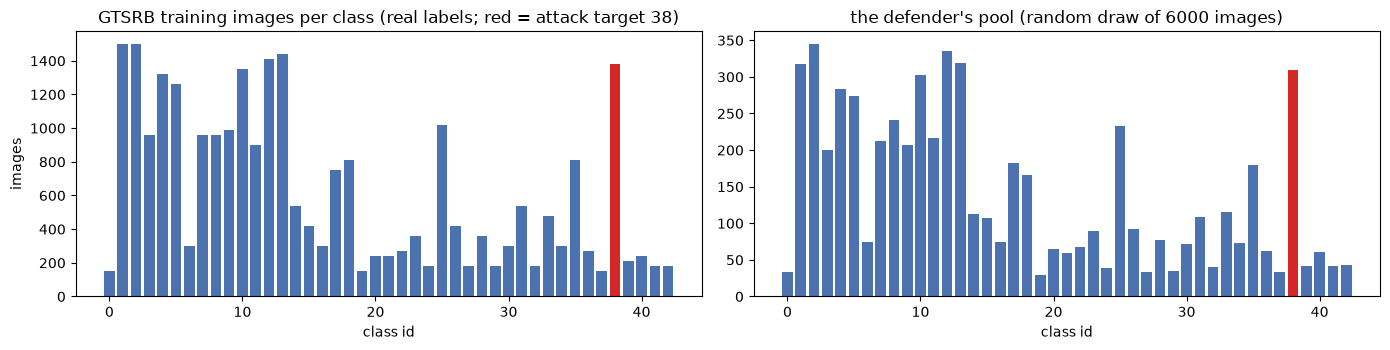

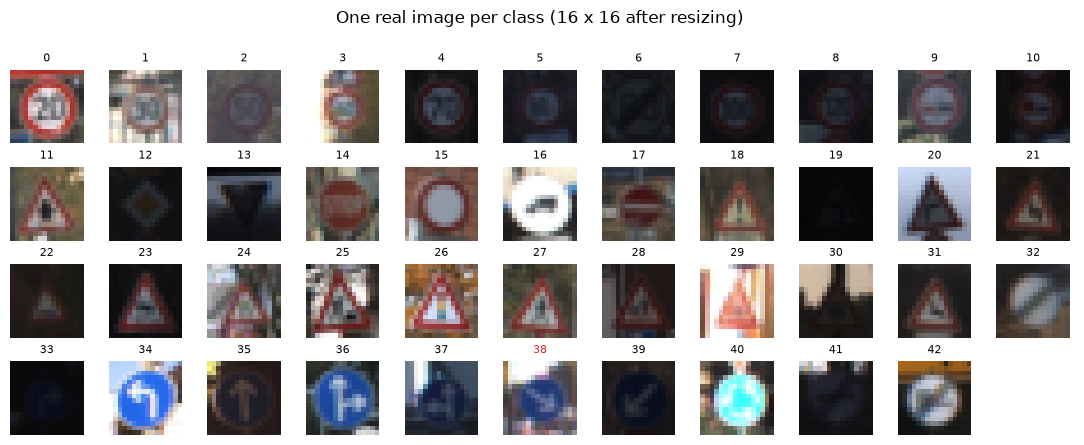

In [7]:
# ---- shape, feature names, original labels, class counts of every data set used
CLASS_NAMES = {38: "keep right"}                      # only the target class is named; the mirror gives integer labels 0..42
print("GTSRB (Hugging Face mirror tanganke/gtsrb), images resized to %d x %d x 3" % (IMG, IMG))
print("  train images :", xtr_all.shape, " labels:", ytr_all.shape, " | test images:", xte_all.shape, " labels:", yte_all.shape)
print("  'features'   : %d raw pixel values per image (R,G,B of %d x %d pixels, 0..255); no tabular feature names exist" % (IMG * IMG * 3, IMG, IMG))
print("  original label values:", sorted(set(ytr_all.tolist()))[:5], "...", sorted(set(ytr_all.tolist()))[-3:], "(43 traffic-sign classes, 0..42)")
cnt_train = np.bincount(ytr_all, minlength=NC); cnt_pool = np.bincount(y_clean, minlength=NC); cnt_test = np.bincount(yte, minlength=NC)
print("  train class counts: min %d, max %d, class %d ('keep right') has %d" % (cnt_train.min(), cnt_train.max(), TARGET, cnt_train[TARGET]))
print("  pool  (defender's data, N=%d) class counts: min %d, max %d, class %d has %d" % (len(y_clean), cnt_pool.min(), cnt_pool.max(), TARGET, cnt_pool[TARGET]))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
cols = ["#d62728" if c == TARGET else "#4c72b0" for c in range(NC)]
ax[0].bar(range(NC), cnt_train, color=cols); ax[0].set_title("GTSRB training images per class (real labels; red = attack target 38)"); ax[0].set_xlabel("class id"); ax[0].set_ylabel("images")
ax[1].bar(range(NC), cnt_pool, color=cols); ax[1].set_title("the defender's pool (random draw of %d images)" % len(y_clean)); ax[1].set_xlabel("class id")
plt.tight_layout(); plt.show()

# one real example of every class
fig, axes = plt.subplots(4, 11, figsize=(11, 4.4))
for c, a in zip(range(NC + 1), axes.ravel()):
    a.axis("off")
    if c < NC: a.imshow(X_clean[np.where(y_clean == c)[0][0]]); a.set_title(str(c), fontsize=8, color="#d62728" if c == TARGET else "black")
plt.suptitle("One real image per class (16 x 16 after resizing)", y=1.0); plt.tight_layout(); plt.show()

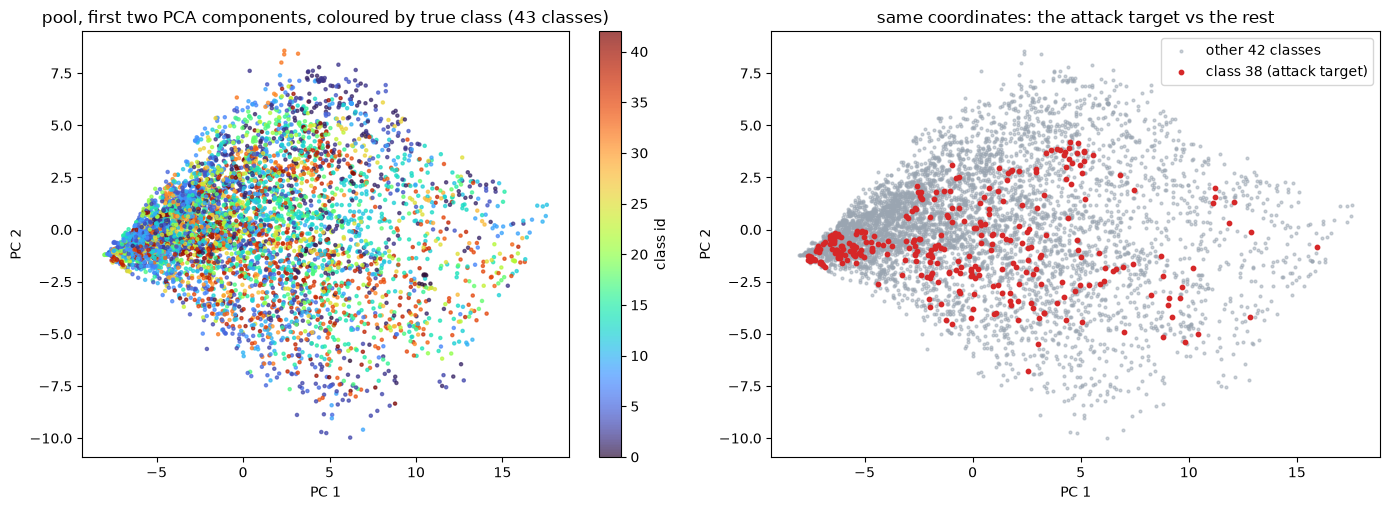

In [8]:
# ---- 2-D scatter of real observations coloured by ground-truth class.
# PCA is fitted on the pool (all of it is training data) and applied to the clean pool and, below, to the poisoned pools.
# NOTE: the Q-WAN and the domain model do not use angle encoding (the Q-WAN inputs are clamped spins, the domain model is classical),
# so the usual "scale the PCA coordinates to [0, pi]" panel does not apply here; the second figure shows the actual Q-WAN input instead.
pca = PCA(n_components=2, random_state=SEED).fit(X_clean.reshape(len(X_clean), -1) / 255.0)
def proj(X): return pca.transform(X.reshape(len(X), -1) / 255.0)
Z = proj(X_clean)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
sc = ax[0].scatter(Z[:, 0], Z[:, 1], c=y_clean, cmap="turbo", s=5, alpha=0.7); ax[0].set_title("pool, first two PCA components, coloured by true class (43 classes)")
plt.colorbar(sc, ax=ax[0], label="class id")
ax[1].scatter(Z[y_clean != TARGET, 0], Z[y_clean != TARGET, 1], c="#9aa5b1", s=4, alpha=0.5, label="other 42 classes")
ax[1].scatter(Z[y_clean == TARGET, 0], Z[y_clean == TARGET, 1], c="#d62728", s=10, label="class 38 (attack target)"); ax[1].legend(); ax[1].set_title("same coordinates: the attack target vs the rest")
for a in ax: a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
plt.tight_layout(); plt.show()

The same real images after poisoning (largest ratio of the current run). Top row: coloured by the label the *defender sees*: for label flipping and
BadNets, images of all kinds of signs now carry label 38 (orange-red in the colour map) and are scattered over the whole plane. Bottom row: the hidden ground truth, which is exactly what the defences try to recover.
Narcissus poisons only images of class 38 itself, which is why there is so little to see in pixel space: the poisoned images are *correctly labelled*.

LF        :   600 poisoned of 6000 (10.00%); observed label counts of the poisoned images: {np.int64(38): np.int64(600)}
BadNets   :  1800 poisoned of 6000 (30.00%); observed label counts of the poisoned images: {np.int64(38): np.int64(1800)}
Narcissus :    93 poisoned of 6000 (1.55%); observed label counts of the poisoned images: {np.int64(38): np.int64(93)}


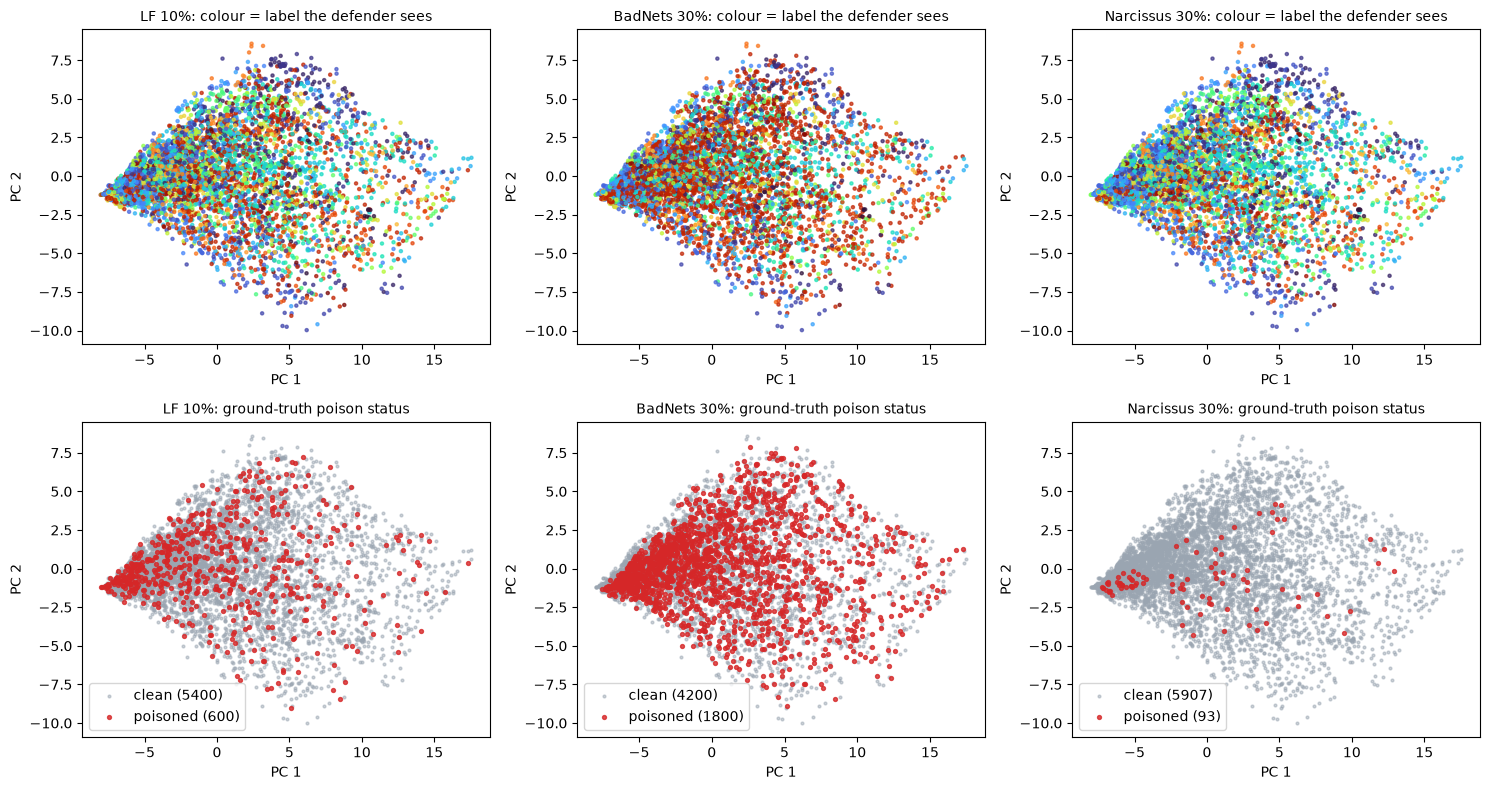

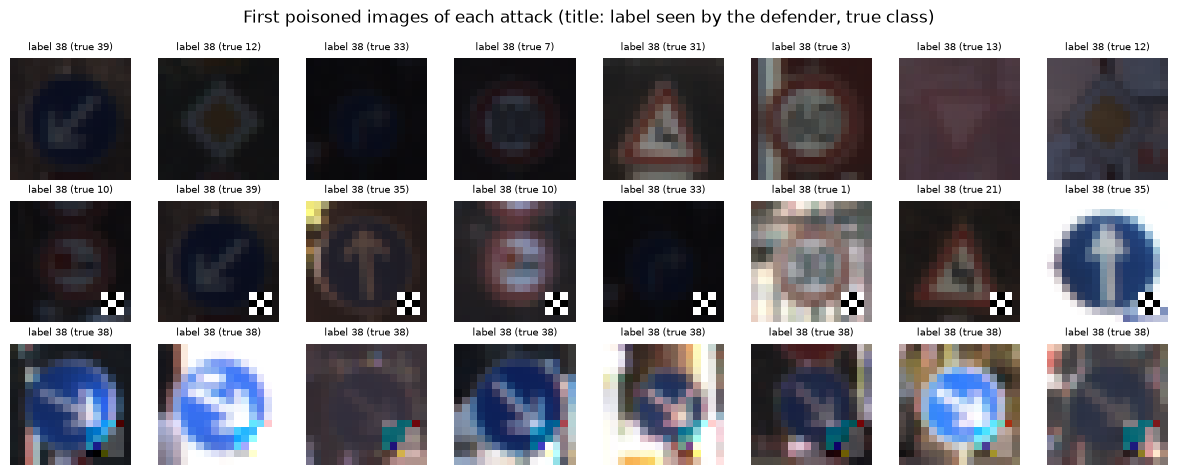

In [9]:
# ---- the same real images after the three attacks (largest ratio of this run). Class scatter: observed (possibly flipped) label vs poison status.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
EX = {}
for k, att in enumerate(["LF", "BadNets", "Narcissus"]):
    ratio = RATIOS[att][-1]; Xp, yp, isp = poison(att, ratio, X_clean, y_clean, np.random.default_rng(SEED + 11), DELTA); EX[att] = (Xp, yp, isp)
    Zp = proj(Xp)
    a = axes[0, k]; sc = a.scatter(Zp[:, 0], Zp[:, 1], c=yp, cmap="turbo", s=5, alpha=0.7)
    a.set_title(f"{att} {ratio:.0%}: colour = label the defender sees", fontsize=10); a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
    a = axes[1, k]; a.scatter(Zp[~isp, 0], Zp[~isp, 1], c="#9aa5b1", s=4, alpha=0.5, label="clean (%d)" % (~isp).sum())
    a.scatter(Zp[isp, 0], Zp[isp, 1], c="#d62728", s=8, alpha=0.8, label="poisoned (%d)" % isp.sum()); a.legend(); a.set_title(f"{att} {ratio:.0%}: ground-truth poison status", fontsize=10); a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
    print(f"{att:10s}: {isp.sum():5d} poisoned of {len(isp)} ({isp.mean():.2%}); observed label counts of the poisoned images: {dict(zip(*np.unique(yp[isp], return_counts=True)))}")
plt.tight_layout(); plt.show()

# what the poisoned images look like (real images, true triggers)
fig, axes = plt.subplots(3, 8, figsize=(12, 4.8))
for r, att in enumerate(["LF", "BadNets", "Narcissus"]):
    Xp, yp, isp = EX[att]; ids = np.where(isp)[0][:8]
    for c, i in enumerate(ids):
        axes[r, c].imshow(Xp[i]); axes[r, c].axis("off"); axes[r, c].set_title(f"label {yp[i]} (true {y_clean[i]})", fontsize=7)
    axes[r, 0].set_ylabel(att)
plt.suptitle("First poisoned images of each attack (title: label seen by the defender, true class)"); plt.tight_layout(); plt.show()

## 3. Metrics and the classical baselines

**NCR.** `ncr(selected, poison_mask)` is the paper's Normalised Corruption Ratio (Eq. 11 and 12): the share of poison in the selected subset divided by the share
of poison in the whole pool. Random selection gives about 100 %.

**Baselines** (paper Section 5; the original code of none of them is used):
- **DCM**: features of a proxy network trained on the poisoned pool; keep the samples closest to the mean of their (observed) class.
- **LossScan**: keep the samples with the smallest loss of a proxy model after *early* training (here the first quarter of the epochs, `LOSSSCAN_EPOCHS`). The paper's text says it removes samples with abnormally high loss; the
  same ranking is obtained by keeping the lowest losses.
- **Autoencoder outlier**: keep the samples with the smallest reconstruction error of a dense autoencoder on raw pixels.
- **Meta-Sift-style** (run later in the grid): the same bilevel hypergradient as Q-Detection, but every sample has its own free weight instead of a weight network.

The plot shows, for one BadNets example, where poisoned and clean samples sit on the loss axis. This scalar is the *only* thing the Q-WAN sees.

In [10]:
def ncr(sel, isp):
    """Normalised Corruption Ratio (paper Eq. 11-12): CR of the selected subset divided by CR of a random subset (= poison fraction of the pool), in %."""
    return float(isp[sel].mean() / isp.mean() * 100.0)

def evaluate(m, xte, yte, attack=None, delta=None):
    """overall accuracy, accuracy on label 38 (paper Fig. 1), and attack success rate (non-target test images -> label 38)."""
    pr = predict(m, xte).argmax(1).numpy(); nt = yte != TARGET
    if attack == "BadNets": pa = predict(m, badnets_trigger(xte[nt])).argmax(1).numpy()
    elif attack == "Narcissus": pa = predict(m, apply_trigger(xte[nt], delta)).argmax(1).numpy()
    else: pa = pr[nt]
    return dict(acc=float((pr == yte).mean()), acc38=float((pr[yte == TARGET] == TARGET).mean()), asr=float((pa == TARGET).mean()))

# ------------------------------------------------------------------ classical baselines (paper Section 5)
def sel_random(n, K, seed): return np.random.default_rng(seed).choice(n, K, replace=False)

def sel_dcm(phi, yp, K):
    """DCM: distance of each sample's feature vector (last hidden layer of a proxy model trained on the poisoned pool) to the mean of its
    (observed) class, normalised by the class median; the K closest samples are kept."""
    phi = phi.numpy(); d = np.zeros(len(phi))
    for c in np.unique(yp):
        i = yp == c; dist = np.linalg.norm(phi[i] - phi[i].mean(0), axis=1); d[i] = dist / (np.median(dist) + 1e-8)
    return np.argsort(d)[:K]

def sel_lossscan(loss, K):
    """LossScan: per-sample loss of a proxy model after EARLY training; the K samples with the smallest loss are kept."""
    return np.argsort(loss.numpy())[:K]

def sel_autoencoder(X, K, seed=0, epochs=8):
    """Autoencoder outlier detection: reconstruction error of a dense autoencoder on raw pixels; K smallest errors are kept."""
    torch.manual_seed(seed); Xf = torch.from_numpy(X).float().reshape(len(X), -1) / 255.0; D = Xf.shape[1]
    ae = nn.Sequential(nn.Linear(D, 128), nn.ReLU(), nn.Linear(128, 32), nn.ReLU(), nn.Linear(32, 128), nn.ReLU(), nn.Linear(128, D), nn.Sigmoid())
    opt = torch.optim.Adam(ae.parameters(), 1e-3)
    for ep in range(epochs):
        perm = torch.randperm(len(Xf))
        for i in range(0, len(perm), 128):
            b = perm[i:i + 128]; opt.zero_grad(); F.mse_loss(ae(Xf[b]), Xf[b]).backward(); opt.step()
    with torch.no_grad(): err = ((ae(Xf) - Xf) ** 2).mean(1).numpy()
    return np.argsort(err)[:K]

proxy models trained in 7 s


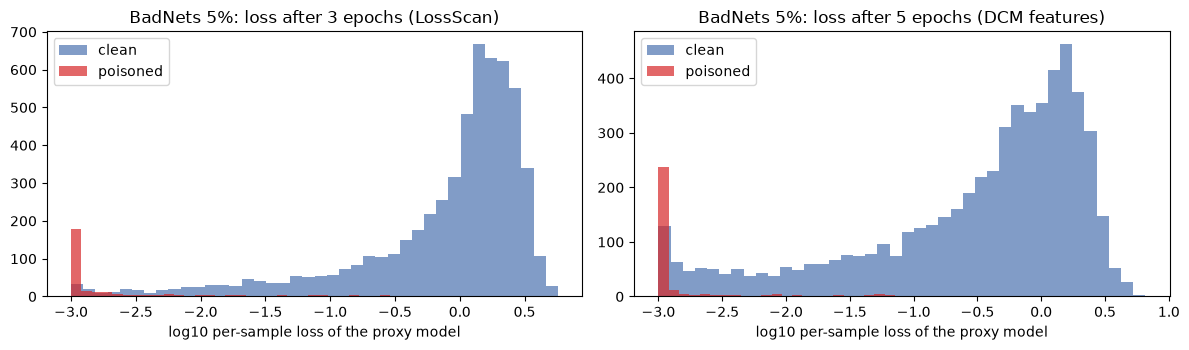

The Q-WAN sees exactly this scalar (as 16 spins). Backdoored images are LEARNED by the model, so their loss is not high; whether a loss-only weight
network can still separate them depends on training the domain model with the weights (the Q-Detection loop), not on a model trained blindly.


In [11]:
# ---- one worked example: proxy model, per-sample loss, and the three classical selections on a BadNets pool
att, ratio = "BadNets", RATIOS["BadNets"][0]
Xp, yp, isp = poison(att, ratio, X_clean, y_clean, np.random.default_rng(SEED + 11), DELTA)
t0 = time.time(); proxy5 = train_model(Xp, yp, "mlp", epochs=5, seed=SEED); phi5, loss5 = feats_losses(proxy5, Xp, yp)
proxy1 = train_model(Xp, yp, "mlp", epochs=LOSSSCAN_EPOCHS, seed=SEED); _, loss1 = feats_losses(proxy1, Xp, yp)
print(f"proxy models trained in {time.time() - t0:.0f} s")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, L, nm in zip(ax, (loss1.numpy(), loss5.numpy()), (f"after {LOSSSCAN_EPOCHS} epochs (LossScan)", "after 5 epochs (DCM features)")):
    a.hist(np.log10(L[~isp] + 1e-3), bins=40, alpha=0.7, label="clean", color="#4c72b0"); a.hist(np.log10(L[isp] + 1e-3), bins=40, alpha=0.7, label="poisoned", color="#d62728")
    a.set_xlabel("log10 per-sample loss of the proxy model"); a.set_title(f"{att} {ratio:.0%}: loss {nm}"); a.legend()
plt.tight_layout(); plt.show()
print("The Q-WAN sees exactly this scalar (as 16 spins). Backdoored images are LEARNED by the model, so their loss is not high; whether a loss-only weight")
print("network can still separate them depends on training the domain model with the weights (the Q-Detection loop), not on a model trained blindly.")

## 4. The Q-WAN: a one-hidden-layer Ising network and its QUBO

**The network.** 16 input spins $s_a$ (a thermometer code of the sample's log-loss, clamped), $H$ hidden spins $h_j$ and one output spin $o$, all in $\{-1,+1\}$.
The energy is

$$E(h,o\mid s) = -\sum_{a,j} J^{(1)}_{aj}\, s_a h_j \;-\; \sum_j J^{(2)}_j\, h_j o \;-\; \sum_j b_j h_j \;-\; b_o\, o ,$$

an Ising model in the form of the paper's Eq. 2. Substituting $\sigma = 2x-1$ (Eq. 3) turns it into a QUBO $\min_x x^\top Q x$ over $x\in\{0,1\}^{H+1}$ (Eq. 1),
which is what an annealer or a QAOA circuit minimises. The output of the network is the **weight** $S_i$ = probability that the output spin is $+1$ at the low-energy state, so $S_i \in[0,1]$.

**Training by equilibrium propagation** (Section 3.3). For every sample solve the QUBO twice: the *free* state (all hidden and the output spin relax) and the *guided* state
(the output spin is clamped to its target $t\in\{-1,+1\}$, which in the paper is written as an extra energy term $C(\sigma_y,\hat\sigma_y)$, Eq. 7). The coupling update is the difference of spin correlations,

$$\Delta J_{ab} \;\propto\; \langle \sigma_a\sigma_b\rangle_{\text{guided}} - \langle \sigma_a\sigma_b\rangle_{\text{free}} ,$$

i.e. the sign convention of contrastive Hebbian / equilibrium-propagation learning (Eq. 10 of the paper prints an extra minus sign; with that sign the network would learn the wrong way).

**Solvers.** There is no quantum annealer here. The same QUBO is handled by (a) **simulated annealing** (block-Gibbs sweeps with a falling temperature, a zero-temperature quench at the end, several independent reads),
(b) an **exact Boltzmann solver**: because the hidden spins are only coupled to the output spin, summing over them is a closed form, so the thermal averages are exact (this is the "infinite reads" limit of a perfect annealer and is
what the large grids use for speed), and (c) a **QAOA** circuit for a small network (the QAOA section further below).

In [12]:
# ------------------------------------------------------------------ the Q-WAN as an Ising model / QUBO
THR = torch.linspace(-4.0, 2.5, K_IN)
def thermo(loss):
    """CHOICE: the scalar sample loss is fed to the Q-WAN as K_IN clamped input spins (thermometer code of log-loss)."""
    u = torch.log(loss.clamp_min(1e-2)); return torch.where(u[:, None] > THR[None], 1.0, -1.0)

def ising_energy(s, h, o, J1, J2, bh, bo):
    """E = - s^T J1 h - (J2.h) o - bh.h - bo o,  spins in {-1,+1}  (paper Eq. 2 with a layered coupling matrix)."""
    return -((s @ J1) * h).sum(-1) - (h @ J2) * o - (h * bh).sum(-1) - bo * o

def qubo_matrix(s, J1, J2, bh, bo, lam=0.0, t=0.0):
    """Exact QUBO  E(x) = x^T Q x + const  over x=(x_hidden, x_output) in {0,1}^(H+1), sigma = 2x-1 (paper Eq. 1 and 3), for ONE sample s.
    lam*t is the 'guided excitation' -lam t sigma_o (paper Eq. 7)."""
    H = len(bh); a = (s @ J1 + bh).double(); J2d = J2.double(); bo_eff = float(bo) + lam * t
    Q = torch.zeros(H + 1, H + 1, dtype=torch.float64); const = 0.0
    for j in range(H):
        Q[j, j] += -2 * a[j]; const += float(a[j])
        Q[j, H] += -4 * J2d[j]; Q[j, j] += 2 * J2d[j]; Q[H, H] += 2 * J2d[j]; const += -float(J2d[j])
    Q[H, H] += -2 * bo_eff; const += bo_eff
    return Q, const

def log2cosh(x): return x.abs() + torch.log1p(torch.exp(-2 * x.abs()))

class QWAN:
    """Quantum Weight-Assigning Network: K_IN input spins (clamped) -> H hidden spins -> 1 output spin; weight S = P(output spin = +1).
    solver="sa"    : the free/guided QUBO is solved by simulated annealing (block-Gibbs, `reads` independent runs, then a zero-temperature quench).
    solver="exact" : the Boltzmann distribution at inverse temperature BETA_EXACT is computed exactly. The QUBO is a star graph (given the output
                     spin the hidden spins are independent), so this is the 'infinite reads' limit of a perfect annealer and ~50x cheaper.
    Training: equilibrium propagation (paper Sec. 3.3): free phase vs guided phase with the output spin clamped to the target, update
    dJ ~ <s_a s_b>_guided - <s_a s_b>_free (the usual sign of contrastive Hebbian / EP learning)."""
    def __init__(self, H, seed=0, lr=LR_WAN, solver="exact", sweeps=8, reads=2):
        self.g = torch.Generator().manual_seed(seed); self.H = H; self.solver = solver; self.sweeps = sweeps; self.reads = reads
        self.lr = lr * (20.0 / max(H, 20) if LR_SCALE_BY_WIDTH else 1.0)          # CHOICE: the output logit is a sum over H hidden spins, so the step size is scaled by 1/H (reference H = 20) to give every width the same learning speed in function space
        self.J1 = torch.randn(K_IN, H, generator=self.g) / math.sqrt(K_IN)
        self.J2 = torch.randn(H, generator=self.g) / math.sqrt(H) * 2
        self.bh = torch.zeros(H); self.bo = torch.zeros(()); self.calls = 0
    # -- simulated annealing (a classical stand-in for the quantum annealer) ---------------------------------
    def anneal(self, s, t=None, reads=None, sweeps=None):
        reads = reads or self.reads; sweeps = sweeps or self.sweeps; B = s.shape[0]; fin = s @ self.J1 + self.bh
        h = torch.where(torch.rand(reads, B, self.H, generator=self.g) < 0.5, 1.0, -1.0)
        o = torch.where(torch.rand(reads, B, generator=self.g) < 0.5, 1.0, -1.0) if t is None else t[None].expand(reads, B).clone()
        for b in torch.logspace(math.log10(BETA_LOW), math.log10(BETA_HIGH), sweeps):
            field = fin[None] + o[..., None] * self.J2
            h = torch.where(torch.rand(h.shape, generator=self.g) < torch.sigmoid(2 * b * field), 1.0, -1.0)
            if t is None:
                o = torch.where(torch.rand(o.shape, generator=self.g) < torch.sigmoid(2 * b * (h @ self.J2 + self.bo)), 1.0, -1.0)
        field = fin[None] + o[..., None] * self.J2; h = torch.where(field >= 0, 1.0, -1.0)          # zero-temperature quench
        if t is None:
            o = torch.where(h @ self.J2 + self.bo >= 0, 1.0, -1.0); field = fin[None] + o[..., None] * self.J2; h = torch.where(field >= 0, 1.0, -1.0)
        self.calls += 1
        return h, o
    # -- exact Boltzmann statistics ---------------------------------------------------------------------------
    def stats_exact(self, s, t=None):
        a = s @ self.J1 + self.bh; be = BETA_EXACT; zp, zm = a + self.J2, a - self.J2
        if t is None:
            lw = torch.stack([be * self.bo + log2cosh(be * zp).sum(1), -be * self.bo + log2cosh(be * zm).sum(1)], 1); P = torch.softmax(lw, 1)[:, 0]
        else: P = (t > 0).float()
        hp, hm = torch.tanh(be * zp), torch.tanh(be * zm)
        return P, P[:, None] * hp + (1 - P[:, None]) * hm, P[:, None] * hp - (1 - P[:, None]) * hm     # P(o=+1), <h>, <h o>
    @torch.no_grad()
    def weights(self, loss, reads=None):
        s = thermo(loss)
        if self.solver == "exact": self.calls += 1; return self.stats_exact(s)[0]
        h, o = self.anneal(s, None, reads); return (1 + o.mean(0)) / 2
    @torch.no_grad()
    def train_step(self, loss, target):
        s = thermo(loss); B = len(s)
        if self.solver == "exact":
            Pf, mhf, mhof = self.stats_exact(s); Pg, mhg, mhog = self.stats_exact(s, target); of = 2 * Pf - 1; self.calls += 2
        else:
            hf, o_f = self.anneal(s, None); hg, o_g = self.anneal(s, target)
            mhf, mhg = hf.mean(0), hg.mean(0); mhof = (hf * o_f[..., None]).mean(0); mhog = (hg * o_g[..., None]).mean(0); of = o_f.mean(0)
        self.J1 += self.lr * s.T @ (mhg - mhf) / B
        self.J2 += self.lr * (mhog - mhof).mean(0)
        self.bh += self.lr * (mhg - mhf).mean(0)
        self.bo += self.lr * (target - of).mean()

class MLPWAN:
    """Ablation: the same K_IN -> H -> 1 architecture trained classically by back-propagation (not an Ising model)."""
    def __init__(self, H, seed=0, lr=LR_WAN):
        torch.manual_seed(seed); self.net = nn.Sequential(nn.Linear(K_IN, H), nn.Tanh(), nn.Linear(H, 1)); self.opt = torch.optim.Adam(self.net.parameters(), lr * 0.1); self.calls = 0
    @torch.no_grad()
    def weights(self, loss, reads=None): return torch.sigmoid(self.net(thermo(loss)).squeeze(-1))
    @torch.enable_grad()
    def train_step(self, loss, target):
        self.opt.zero_grad(); F.binary_cross_entropy_with_logits(self.net(thermo(loss)).squeeze(-1), (target + 1) / 2).backward(); self.opt.step()

**Four checks before anything is trained.** (1) The QUBO matrix reproduces the Ising energy of all 512 configurations of a 9-spin network. (2) The closed-form ground state of the
star-shaped QUBO equals brute-force enumeration. (3) Simulated annealing finds the exact ground state in a measured share of its reads. (4) On a 500-hidden-neuron network, the output weights from simulated annealing
and from the exact solver are strongly correlated (they are not identical because the annealing schedule and the exact solver use different final temperatures).

In [13]:
# ---- unit tests on a small Q-WAN (H = 8 hidden spins -> 9 qubits, small enough to enumerate all 2^9 states)
def all_spins(n):
    """(2^n, n) Z-eigenvalues: +1 for bit 0, -1 for bit 1; qubit q is bit q of the basis index (Qiskit little endian)."""
    idx = torch.arange(2 ** n); return 1.0 - 2.0 * ((idx[:, None] >> torch.arange(n)[None]) & 1).float()

def energy_table(w, s, t=None, lam=0.0):
    """Ising energies of ALL 2^(H+1) configurations (qubits 0..H-1 hidden, qubit H output) for every sample in s."""
    H = w.H; Sg = all_spins(H + 1); Sh, So = Sg[:, :H], Sg[:, H]
    E = -((s @ w.J1 + w.bh) @ Sh.T) - ((Sh @ w.J2) + w.bo)[None] * So[None]
    if t is not None: E = E - lam * t[:, None] * So[None]
    return E

torch.manual_seed(SEED)
w_small = QWAN(8, seed=1, solver="sa"); w_small.J1 *= 2
s_small = thermo(torch.rand(6) * 3)
E_all = energy_table(w_small, s_small); Sg = all_spins(9); X01 = (1 + Sg) / 2
# (1) the QUBO  x^T Q x + const  reproduces the Ising energy of every one of the 512 configurations
errs = []
for b in range(3):
    Q, c = qubo_matrix(s_small[b], w_small.J1, w_small.J2, w_small.bh, w_small.bo)
    errs.append(float((torch.einsum("ni,ij,nj->n", X01.double(), Q, X01.double()) + c - E_all[b].double()).abs().max()))
print("(1) max |QUBO - Ising| over all 512 states and 3 samples: %.1e" % max(errs))
assert max(errs) < 1e-4
# (2) closed-form ground state of the star-graph QUBO == brute-force minimum
for b in range(3):
    a = s_small[b] @ w_small.J1 + w_small.bh
    gs = min(-(a + w_small.J2 * o).abs().sum() - w_small.bo * o for o in (1.0, -1.0))
    assert abs(float(gs) - float(E_all[b].min())) < 1e-4
print("(2) closed-form ground state equals brute-force enumeration: OK")
# (3) how often does one simulated-annealing read reach the ground state?
hit = tot = 0
for b in range(6):
    h, o = w_small.anneal(s_small[b:b + 1], None, reads=64, sweeps=8)
    Es = ising_energy(s_small[b:b + 1], h, o, w_small.J1, w_small.J2, w_small.bh, w_small.bo).squeeze(1)
    hit += int((Es <= E_all[b].min() + 1e-5).sum()); tot += 64
print(f"(3) simulated annealing reaches the exact ground state in {hit / tot:.0%} of reads (8 sweeps)")
# (4) SA output statistics vs the exact Boltzmann solver on a larger Q-WAN (H = 500, annealed at the final inverse temperature)
w_big = QWAN(500, seed=2, solver="sa", sweeps=24, reads=64); Lb = torch.rand(40) * 3
S_sa = w_big.weights(Lb); S_ex = QWAN.stats_exact(w_big, thermo(Lb))[0]
print(f"(4) H=500: weight from SA reads vs exact Boltzmann marginal: correlation {np.corrcoef(S_sa.numpy(), S_ex.numpy())[0, 1]:.2f}, "
      f"mean |difference| {float((S_sa - S_ex).abs().mean()):.2f} (the SA schedule ends at beta={BETA_HIGH}, the exact solver uses beta={BETA_EXACT})")

(1) max |QUBO - Ising| over all 512 states and 3 samples: 3.8e-06
(2) closed-form ground state equals brute-force enumeration: OK
(3) simulated annealing reaches the exact ground state in 86% of reads (8 sweeps)


(4) H=500: weight from SA reads vs exact Boltzmann marginal: correlation 0.75, mean |difference| 0.12 (the SA schedule ends at beta=4.0, the exact solver uses beta=2.0)


**A fifth check: does the learning rule work?** Before the Q-WAN is used inside the poisoning loop, it is trained on a deliberately simple task with *synthetic* loss values (this cell is a unit test of the training rule only and
is not part of any data experiment): "weight 1 if the loss is below 0.8, weight 0 otherwise". An AUC near 1 means the equilibrium-propagation update (free vs guided phase) points the right way, for both the annealing sampler and the exact solver.

In [14]:
# ---- unit test of the learning rule (synthetic numbers, NOT part of the data experiments): can the Q-WAN learn "weight 1 if loss < 0.8, else 0"?
from sklearn.metrics import roc_auc_score
torch.manual_seed(SEED); LC_ROWS = []
for solver in ("exact", "sa"):
    for h in (20, 500):
        w = QWAN(h, seed=0, solver=solver)
        for step in range(200):
            L = torch.exp(torch.randn(BATCH) - 0.5); w.train_step(L, torch.where(L < 0.8, 1.0, -1.0))
        Lt = torch.exp(torch.randn(2000) - 0.5); lab = (Lt < 0.8).numpy(); S = w.weights(Lt, reads=16).numpy()
        LC_ROWS.append(dict(solver=solver, hidden=h, AUC=round(roc_auc_score(lab, S), 3), mean_weight_low_loss=round(float(S[lab].mean()), 2), mean_weight_high_loss=round(float(S[~lab].mean()), 2)))
print(pd.DataFrame(LC_ROWS).to_string(index=False))

solver  hidden   AUC  mean_weight_low_loss  mean_weight_high_loss
 exact      20 0.989                  0.92                   0.07
 exact     500 0.989                  0.95                   0.10
    sa      20 0.989                  0.96                   0.10
    sa     500 0.944                  1.00                   0.12


## 5. Q-Detection: the bilevel loop

For each mini-batch of 179 samples (the paper's batch size) the loop below performs the paper's three stages:

1. **Losses and weights.** The domain model gives every sample a loss $L_i$; the Q-WAN turns it into a weight $S_i$.
2. **Adversarial Filtering (Eq. 5).** The outer objective is $F(S)=\sum_j (1-S_j)\,L_j(\theta')$ where $\theta'$ is the virtual model after one step on the $S$-weighted loss (**Selective Learning**, Eq. 6).
   Its derivative with respect to $S_i$ (the *hypergradient*) is available in closed form because the virtual model is the linear head:
   $\partial F/\partial S_i = -L_i(\theta') - \eta\sum_j (1-S_j)\,\langle \nabla L_j(\theta'),\nabla L_i(\theta)\rangle$ (the virtual step uses the batch mean of the gradients, so in the code the inner-product sum is divided by the batch size).
   A positive value means "weighting this sample more raises the loss of the unselected ones" (the sample behaves like clean data). The values are split into two groups by Otsu's rule and the groups become the targets $t=\pm1$ of the Q-WAN output spin.
   *This target construction is a choice of this notebook; the paper only says that the guided state is "$\psi^*$ or $\theta^*(\psi)$".*
3. **Actual update.** The domain model takes a step on the $S$-weighted loss (Eq. 6 applied to the domain model).

After the last epoch the Q-WAN scores the whole pool with the final domain model's losses and the $K$ highest weights are the selected clean subset (ties broken at random). The **Meta-Sift-style** baseline uses the same
hypergradient but stores one weight per sample ($w_i \leftarrow w_i \pm 0.2$) instead of a network; the **classical WAN** replaces the Ising network by a tanh MLP of the same shape trained by back-propagation, to separate "weight network" from "trained as a QUBO".

In [15]:
# ------------------------------------------------------------------ Q-Detection: virtual update + Q-WAN training + actual update
def otsu_split(v):
    """1-D two-cluster split (Otsu). True = upper cluster. Used to turn hypergradients into +/-1 targets for the output spin."""
    v = np.asarray(v, float); n = len(v)
    if v.std() < 1e-12: return np.ones(n, bool)
    o = np.sort(v); cs = np.cumsum(o); k = np.arange(1, n); m0 = cs[:-1] / k; m1 = (cs[-1] - cs[:-1]) / (n - k)
    j = int(np.argmax((k / n) * (1 - k / n) * (m0 - m1) ** 2)); return v > 0.5 * (o[j] + o[j + 1])

def hypergrad(phi, W, b, r, S, Y1, eta):
    """dF/dS_i of the outer objective F(S) = sum_j (1 - S_j) L_j(theta'),  theta' = theta - eta * sum_i S_i grad L_i  (paper Eq. 4/5;
    virtual step on the linear head only, so every gradient inner product is analytic: <g_i, g_j> = (r_i . r_j)(phi_i . phi_j + 1))."""
    B = len(S); Wn = W - eta * (S[:, None] * r).T @ phi / B; bn = b - eta * (S[:, None] * r).sum(0) / B
    pn = torch.softmax(phi @ Wn.T + bn, 1); rn = pn - Y1; Ln = -(torch.log(pn.clamp_min(1e-9)) * Y1).sum(1)
    m = ((r @ rn.T) * (phi @ phi.T + 1.0)) @ (1 - S) / B
    return -Ln - eta * m

def run_detection(Xp, yp, wan, epochs, K, seed=0, table=False, alpha=0.2, isp=None):
    """Q-Detection (and, with table=True, a Meta-Sift-style classical variant where every sample owns a free weight).
    Per mini-batch: (1) domain model -> losses; (2) Q-WAN maps losses to weights S (free phase); (3) virtual-update stage: hypergradient of
    the outer objective w.r.t. S (adversarial filtering) gives +/-1 targets, the Q-WAN is trained by equilibrium propagation;
    (4) selective-learning / actual-update stage: the domain model takes a step on the S-weighted loss. Finally the Q-WAN scores the whole
    pool with the final domain model and the K highest weights are the selected 'clean' subset."""
    torch.manual_seed(seed); n = len(Xp); dom = Net(); opt = torch.optim.Adam(dom.parameters(), LR_DOMAIN)
    Xt, Yt = to_t(Xp), torch.from_numpy(yp); Y1all = F.one_hot(Yt, NC).float()
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR_DOMAIN, total_steps=epochs * math.ceil(n / BATCH))
    wtab = torch.full((n,), 0.5); hist = []
    for ep in range(epochs):
        perm = torch.randperm(n); auc = []
        for i in range(0, n, BATCH):
            b = perm[i:i + BATCH]
            phi = dom.features(Xt[b]); logits = dom.head(phi); L = F.cross_entropy(logits, Yt[b], reduction="none")
            with torch.no_grad():
                Y1 = Y1all[b]; r = torch.softmax(logits, 1) - Y1
                if hasattr(wan, 'tune') and i == 0: wan.tune(L.detach())          # gate-model Q-WAN: re-tune the QAOA angles once per epoch
                S = wtab[b] if table else wan.weights(L.detach())
                h = hypergrad(phi.detach(), dom.head.weight.detach(), dom.head.bias.detach(), r, S, Y1, ETA_VIRTUAL)
                tgt = torch.from_numpy(np.where(otsu_split(h.numpy()), 1.0, -1.0)).float()
                if isp is not None:
                    ip = isp[b.numpy()]
                    if 0 < ip.sum() < len(ip): auc.append(roc_auc_score(~ip, h.numpy()))
                if table: wtab[b] = (wtab[b] + alpha * tgt).clamp(0, 1)
                else: wan.train_step(L.detach(), tgt)
            opt.zero_grad(); (S * L).mean().backward(); opt.step(); sched.step()
        hist.append(float(np.mean(auc)) if auc else np.nan)
    dom.eval(); _, Lall = feats_losses(dom, Xp, yp)
    S = wtab if table else wan.weights(Lall, reads=16)
    key = S.numpy() + 1e-6 * np.random.default_rng(seed).random(n)          # random tie-break
    return np.argsort(-key)[:K], dom, S.numpy(), hist

## 6. Experiments: Table 1 of the paper

Every attack and poison ratio of `RATIOS`, every defence. Q-Detection runs with 20, 500 and 5000 hidden spins (qubits) and the exact solver; `QD_H500` is the analogue of the paper's "Q-Det. 500 qubits"
columns, `QD_H5000` of "Q-Det. QA 5000 qubits". One seed in the table; section 9 repeats the contested cells with other seeds. The next cell runs the whole grid and prints one line per cell.

In [16]:
# ------------------------------------------------------------------ the experiment grid (Table 1 of the paper)
PAPER_T1 = {  # (attack, poison ratio in %) -> NCR % reported by the paper; Q-Det columns: CQPC 500 qubits, QA 500 qubits, QA 5000 qubits
    ("LF", 3):  dict(DCM=15.24, LossScan=0.00, AutoEncoder=76.58, MetaSift=0, QD_CQPC500=0, QD_QA500=0, QD_QA5000=0),
    ("LF", 5):  dict(DCM=18.06, LossScan=0.00, AutoEncoder=108.91, MetaSift=0, QD_CQPC500=0, QD_QA500=0, QD_QA5000=0),
    ("LF", 10): dict(DCM=38.17, LossScan=0.00, AutoEncoder=106.55, MetaSift=0, QD_CQPC500=0, QD_QA500=0, QD_QA5000=0),
    ("LF", 20): dict(DCM=62.27, LossScan=5.61, AutoEncoder=115.65, MetaSift=0, QD_CQPC500=0, QD_QA500=0, QD_QA5000=0),
    ("LF", 30): dict(DCM=87.99, LossScan=6.59, AutoEncoder=118.25, MetaSift=0, QD_CQPC500=0, QD_QA500=0, QD_QA5000=0),
    ("Narcissus", 3):  dict(DCM=0, LossScan=94.39, AutoEncoder=0, MetaSift=0, QD_CQPC500=0, QD_QA500=0, QD_QA5000=0),
    ("Narcissus", 5):  dict(DCM=0, LossScan=132.57, AutoEncoder=0, MetaSift=0, QD_CQPC500=0, QD_QA500=0, QD_QA5000=0),
    ("Narcissus", 10): dict(DCM=0, LossScan=235.59, AutoEncoder=0, MetaSift=0, QD_CQPC500=0, QD_QA500=0, QD_QA5000=0),
    ("Narcissus", 20): dict(DCM=0, LossScan=197.89, AutoEncoder=0, MetaSift=0, QD_CQPC500=0, QD_QA500=0, QD_QA5000=0),
    ("Narcissus", 30): dict(DCM=0, LossScan=188.47, AutoEncoder=0, MetaSift=0, QD_CQPC500=180.0, QD_QA500=267.0, QD_QA5000=0),
    ("BadNets", 1):  dict(DCM=0, LossScan=0, AutoEncoder=0, MetaSift=0, QD_CQPC500=0, QD_QA500=0, QD_QA5000=0),
    ("BadNets", 3):  dict(DCM=30.49, LossScan=0, AutoEncoder=0, MetaSift=0, QD_CQPC500=0, QD_QA500=0, QD_QA5000=0),
    ("BadNets", 5):  dict(DCM=18.05, LossScan=0, AutoEncoder=0, MetaSift=0, QD_CQPC500=0, QD_QA500=0, QD_QA5000=0),
    ("BadNets", 8):  dict(DCM=16.24, LossScan=0, AutoEncoder=0, MetaSift=0, QD_CQPC500=0, QD_QA500=0, QD_QA5000=0),
    ("BadNets", 10): dict(DCM=16.95, LossScan=0, AutoEncoder=0, MetaSift=0, QD_CQPC500=110.14, QD_QA500=330.0, QD_QA5000=0),
    ("BadNets", 30): dict(DCM=57.21, LossScan=121.07, AutoEncoder=0, MetaSift=0, QD_CQPC500=231.24, QD_QA500=365.57, QD_QA5000=0),
}
MAIN_H = 500                                              # the "500 qubit" Q-WAN of the paper's main table
METHODS = ["Random", "DCM", "LossScan", "AutoEncoder", "MetaSift"] + [f"QD_H{h}" for h in HIDDEN_SIZES] + ["QD_H5000", "ClassicalWAN_H500"]
METHODS = list(dict.fromkeys(METHODS))

def run_methods(Xp, yp, isp, seed, which=None):
    """Select K_SEL samples with every method; returns {method: (indices, seconds)}."""
    K = K_SEL; out = {}; which = which or METHODS
    def timed(name, fn):
        if name in which:
            t = time.time(); sel = fn(); out[name] = (np.asarray(sel), time.time() - t)
    if any(m in which for m in ("DCM", "LossScan")):
        p5 = train_model(Xp, yp, "mlp", epochs=5, seed=seed); phi5, _ = feats_losses(p5, Xp, yp)
        p1 = train_model(Xp, yp, "mlp", epochs=LOSSSCAN_EPOCHS, seed=seed); _, l1 = feats_losses(p1, Xp, yp)
        timed("DCM", lambda: sel_dcm(phi5, yp, K)); timed("LossScan", lambda: sel_lossscan(l1, K))
    timed("Random", lambda: sel_random(len(Xp), K, seed))
    timed("AutoEncoder", lambda: sel_autoencoder(Xp, K, seed))
    timed("MetaSift", lambda: run_detection(Xp, yp, None, EPOCHS, K, seed, table=True)[0])
    for h in HIDDEN_SIZES + [5000]:
        timed(f"QD_H{h}", lambda h=h: run_detection(Xp, yp, QWAN(h, seed=seed, solver="exact"), EPOCHS, K, seed)[0])
    timed("ClassicalWAN_H500", lambda: run_detection(Xp, yp, MLPWAN(500, seed=seed), EPOCHS, K, seed)[0])
    return out

RES = {}                                                  # (attack, ratio) -> {method: (sel, seconds)} plus the poisoned pool
t_grid = time.time()
for att, ratios in RATIOS.items():
    for ratio in ratios:
        Xp, yp, isp = poison(att, ratio, X_clean, y_clean, np.random.default_rng(SEED + 11), DELTA)
        t0 = time.time(); res = run_methods(Xp, yp, isp, SEED)
        RES[(att, ratio)] = dict(sel={m: v[0] for m, v in res.items()}, secs={m: v[1] for m, v in res.items()}, Xp=Xp, yp=yp, isp=isp)
        print(f"{att:9s} {ratio:5.0%}  poison {isp.mean():6.2%} of pool | NCR %: " + "  ".join(f"{m}={ncr(v[0], isp):.0f}" for m, v in res.items()) + f"   [{time.time() - t0:.0f} s]", flush=True)
print(f"grid finished in {(time.time() - t_grid) / 60:.1f} min")

LF           5%  poison  5.00% of pool | NCR %: DCM=9  LossScan=0  Random=98  AutoEncoder=78  MetaSift=113  QD_H20=0  QD_H500=18  QD_H5000=2  ClassicalWAN_H500=0   [158 s]


LF          10%  poison 10.00% of pool | NCR %: DCM=50  LossScan=2  Random=104  AutoEncoder=106  MetaSift=144  QD_H20=0  QD_H500=20  QD_H5000=6  ClassicalWAN_H500=0   [169 s]


BadNets      5%  poison  5.00% of pool | NCR %: DCM=49  LossScan=633  Random=98  AutoEncoder=0  MetaSift=118  QD_H20=62  QD_H500=11  QD_H5000=9  ClassicalWAN_H500=336   [154 s]


BadNets     30%  poison 30.00% of pool | NCR %: DCM=191  LossScan=333  Random=105  AutoEncoder=99  MetaSift=138  QD_H20=89  QD_H500=4  QD_H5000=1  ClassicalWAN_H500=176   [177 s]


Narcissus   10%  poison  0.52% of pool | NCR %: DCM=43  LossScan=538  Random=86  AutoEncoder=0  MetaSift=65  QD_H20=86  QD_H500=43  QD_H5000=0  ClassicalWAN_H500=387   [196 s]


Narcissus   30%  poison  1.55% of pool | NCR %: DCM=172  LossScan=652  Random=86  AutoEncoder=0  MetaSift=93  QD_H20=50  QD_H500=0  QD_H5000=0  ClassicalWAN_H500=366   [198 s]


grid finished in 17.5 min


### 6.1 The NCR table

   attack  ratio %  poison % of pool  Random   DCM  LossScan  AutoEncoder  MetaSift  QD_H20  QD_H500  QD_H5000  ClassicalWAN_H500
       LF        5              5.00    97.8   8.9       0.0         77.8     113.3     0.0     17.8       2.2                0.0
       LF       10             10.00   104.4  50.0       2.2        105.6     144.4     0.0     20.0       5.6                0.0
  BadNets        5              5.00    97.8  48.9     633.3          0.0     117.8    62.2     11.1       8.9              335.6
  BadNets       30             30.00   104.8 191.5     333.3         98.5     138.1    88.9      3.7       1.1              176.3
Narcissus       10              0.52    86.0  43.0     537.6          0.0      64.5    86.0     43.0       0.0              387.1
Narcissus       30              1.55    86.0 172.0     652.3          0.0      93.2    50.2      0.0       0.0              365.6


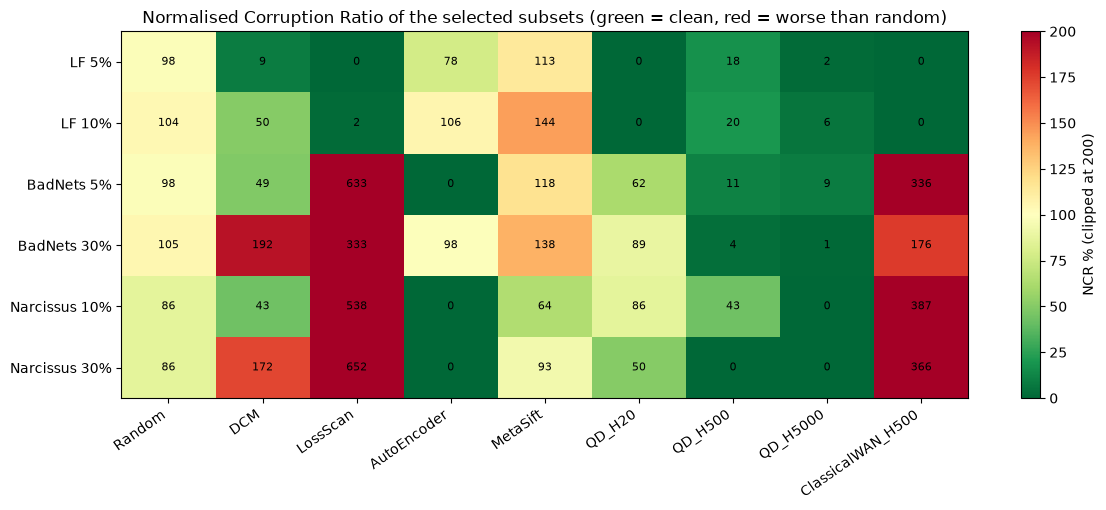

In [17]:
# ---- Table 1 of this notebook (NCR in %, lower is better, 0 = perfectly clean subset, 100 = random)
rows = []
for (att, ratio), r in RES.items():
    row = {"attack": att, "ratio %": int(round(ratio * 100)), "poison % of pool": round(100 * r["isp"].mean(), 2)}
    for m in METHODS: row[m] = round(ncr(r["sel"][m], r["isp"]), 1)
    rows.append(row)
NCR_TABLE = pd.DataFrame(rows); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(NCR_TABLE.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 0.45 * len(NCR_TABLE) + 2.5))
M_ = NCR_TABLE[METHODS].values.astype(float); im = ax.imshow(np.clip(M_, 0, 300), cmap="RdYlGn_r", aspect="auto", vmin=0, vmax=200)
ax.set_xticks(range(len(METHODS))); ax.set_xticklabels(METHODS, rotation=35, ha="right"); ax.set_yticks(range(len(NCR_TABLE)))
ax.set_yticklabels([f"{a} {r}%" for a, r in zip(NCR_TABLE["attack"], NCR_TABLE["ratio %"])])
for i in range(M_.shape[0]):
    for j in range(M_.shape[1]): ax.text(j, i, f"{M_[i, j]:.0f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="NCR % (clipped at 200)"); ax.set_title("Normalised Corruption Ratio of the selected subsets (green = clean, red = worse than random)"); plt.tight_layout(); plt.show()

### 6.2 Cell by cell against the paper

The paper's NCR depends on ResNet-18 on 39,209 images; ours on a 16 x 16 MLP and a few thousand images, so exact numbers cannot match. A cell **agrees** when both fall in the same band
(good <= 25 %, partial <= 75 %, poor > 75 %) or differ by at most 15 points. For the 500-qubit column the paper has two values (CQPC and QA); their mean is used.

In [18]:
# ---- this notebook vs the paper's Table 1, cell by cell
def category(v): return "good" if v <= 25 else ("partial" if v <= 75 else "poor")
MAP = {"DCM": ["DCM"], "LossScan": ["LossScan"], "AutoEncoder": ["AutoEncoder"], "MetaSift": ["MetaSift"],
       f"QD_H{MAIN_H}": ["QD_CQPC500", "QD_QA500"], "QD_H5000": ["QD_QA5000"]}
cmp_rows = []
for (att, ratio), r in RES.items():
    key = (att, int(round(ratio * 100)))
    if key not in PAPER_T1: continue
    for ours, paper_cols in MAP.items():
        if ours not in r["sel"]: continue
        v = ncr(r["sel"][ours], r["isp"]); pv = float(np.mean([PAPER_T1[key][c] for c in paper_cols]))
        cmp_rows.append(dict(attack=att, ratio=key[1], method=ours, paper_NCR=round(pv, 1), notebook_NCR=round(v, 1), diff=round(v - pv, 1),
                             paper_cat=category(pv), notebook_cat=category(v), agree=(category(v) == category(pv)) or abs(v - pv) <= 15))
CMP = pd.DataFrame(cmp_rows)
print(CMP.to_string(index=False))
print()
print("share of cells where the notebook agrees with the paper (same category good<=25 / partial<=75 / poor, or |diff| <= 15 points):")
print(CMP.groupby("method")["agree"].agg(["mean", "sum", "count"]).rename(columns={"mean": "agreement", "sum": "cells agreeing", "count": "cells"}).round(2).to_string())

   attack  ratio      method  paper_NCR  notebook_NCR   diff paper_cat notebook_cat  agree
       LF      5         DCM       18.1           8.9   -9.2      good         good   True
       LF      5    LossScan        0.0           0.0    0.0      good         good   True
       LF      5 AutoEncoder      108.9          77.8  -31.1      poor         poor   True
       LF      5    MetaSift        0.0         113.3  113.3      good         poor  False
       LF      5     QD_H500        0.0          17.8   17.8      good         good   True
       LF      5    QD_H5000        0.0           2.2    2.2      good         good   True
       LF     10         DCM       38.2          50.0   11.8   partial      partial   True
       LF     10    LossScan        0.0           2.2    2.2      good         good   True
       LF     10 AutoEncoder      106.5         105.6   -1.0      poor         poor   True
       LF     10    MetaSift        0.0         144.4  144.4      good         poor  False

## 7. Training a new model on the selected subset (paper Fig. 1)

The paper trains a fresh ResNet-18 on each defence's 4,000 images and plots test accuracy (overall and for label 38) under label flipping. Here a fresh MLP (the same architecture as the domain model) is trained on each selected subset for `FINAL_EPOCHS`
epochs. **"Oracle clean"** is the same model trained on the same number of truly clean images, an upper bound that no defender can reach. The figure of the paper is a bar chart without printed numbers, so only
the qualitative claim "Q-Detection is at least as good as Meta-Sift" can be checked.

128 s
 ratio       method   acc  acc38   asr
     5 Oracle clean 0.501  0.892 0.024
     5       Random 0.452  0.796 0.122
     5          DCM 0.313  0.510 0.158
     5     LossScan 0.270  0.904 0.115
     5  AutoEncoder 0.056  0.510 0.252
     5     MetaSift 0.442  0.994 0.164
     5      QD_H500 0.400  0.726 0.042
    10 Oracle clean 0.480  0.866 0.024
    10       Random 0.414  0.917 0.215
    10          DCM 0.287  0.369 0.223
    10     LossScan 0.280  0.936 0.119
    10  AutoEncoder 0.068  0.522 0.339
    10     MetaSift 0.332  0.981 0.361
    10      QD_H500 0.460  0.924 0.078


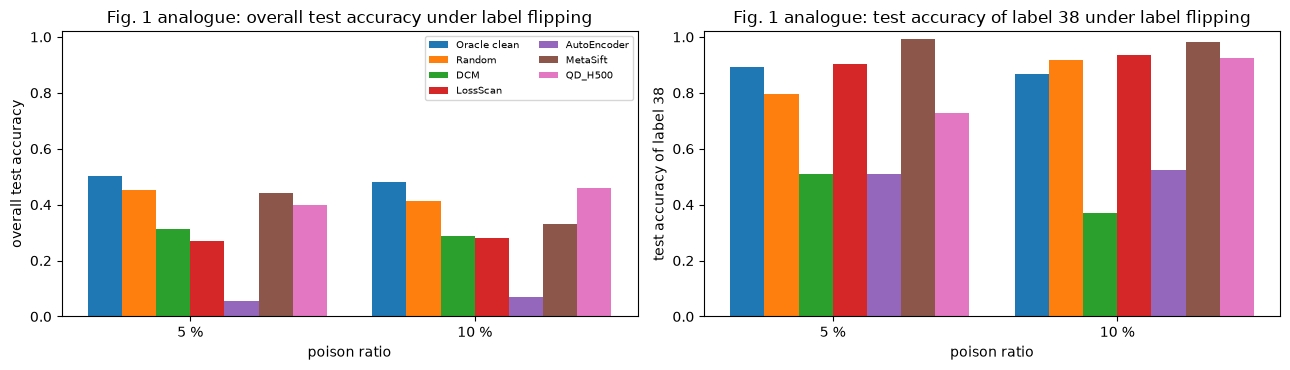

In [19]:
# ---- paper Fig. 1: train a NEW model on each selected subset and test it (label flipping only, as in the paper)
FIG1_METHODS = ["Random", "DCM", "LossScan", "AutoEncoder", "MetaSift", f"QD_H{MAIN_H}"]
fig1_rows = []; t0 = time.time()
for ratio in RATIOS["LF"]:
    r = RES[("LF", ratio)]
    # reference: the same model trained on K_SEL truly clean samples (oracle; not available to a defender)
    clean_idx = np.random.default_rng(SEED).choice(np.where(~r["isp"])[0], K_SEL, replace=False)
    for m in ["Oracle clean"] + FIG1_METHODS:
        sel = clean_idx if m == "Oracle clean" else r["sel"][m]
        cnn = train_model(r["Xp"][sel], r["yp"][sel], "mlp", epochs=FINAL_EPOCHS, seed=SEED)
        fig1_rows.append(dict(ratio=int(round(ratio * 100)), method=m, **evaluate(cnn, xte, yte, "LF")))
FIG1 = pd.DataFrame(fig1_rows); print(f"{time.time() - t0:.0f} s"); print(FIG1.round(3).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8)); order = ["Oracle clean"] + FIG1_METHODS
for a, col, ttl in zip(ax, ("acc", "acc38"), ("overall test accuracy", "test accuracy of label 38")):
    for k, m in enumerate(order):
        d = FIG1[FIG1.method == m]; a.bar(np.arange(len(d)) + k * 0.12, d[col], width=0.12, label=m)
    a.set_xticks(np.arange(len(RATIOS["LF"])) + 0.3); a.set_xticklabels([f"{int(round(r * 100))} %" for r in RATIOS["LF"]]); a.set_xlabel("poison ratio"); a.set_ylabel(ttl); a.set_ylim(0, 1.02); a.set_title(f"Fig. 1 analogue: {ttl} under label flipping")
ax[0].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The main Q-Detection results above come from a QUBO (annealer-style) formulation; no gate circuit is executed there. The paper also states that the same training can run on a gate-model
computer with **QAOA** (Qiskit, limited to about 30 qubits), and this section implements exactly that for a small Q-WAN so that a real quantum circuit is built, drawn and run.

**How the circuit is built.** A Q-WAN with `QAOA_HIDDEN` = 8 hidden spins plus the output spin is **9 qubits** (qubit $j<8$ = hidden spin $j$, qubit 8 = output spin). For one sample the free-phase QUBO is
$H_C = -\sum_j a_j Z_j - \sum_j J^{(2)}_j Z_j Z_8 - b_o Z_8$ with $a_j = (s^\top J^{(1)})_j + b_j$ (the input spins are classical and clamped, so they only enter as local fields).
The circuit is Qiskit's `QAOAAnsatz`: Hadamards on all qubits, then $p = 2$ layers of the cost unitary $e^{-i\gamma_l H_C}$ (RZ and RZZ gates) and the mixer $e^{-i\beta_l\sum_q X_q}$ (RX gates). Measuring in the computational basis gives bit strings;
the best of 64 shots plays the role of an annealer read. The guided phase adds the clamp term $-\lambda\, t\, Z_8$ (with $\lambda = 4$) to $H_C$ instead of fixing the output qubit.

**Assumptions the paper does not settle.** Depth $p = 2$, 64 shots, the 8-spin size (the paper's Qiskit run used 20 neurons), the clamp strength $\lambda$ and how the 4 circuit angles are chosen (here a short COBYLA run on the mean QUBO energy of a batch, repeated once per epoch)
are all choices of this notebook. For speed the many circuits of a batch (one per sample, they differ only in the local fields) are simulated in one batched torch computation; the cell asserts that this simulation equals Qiskit's statevector of the drawn circuit.

In [20]:
# ------------------------------------------------------------------ gate-model version: the same QUBO solved with QAOA
from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import SparsePauliOp, Statevector
from scipy.optimize import minimize

def qaoa_state(E, gammas, betas):
    """Statevector of  |+>^n -> [exp(-i gamma_l E) -> RX(2 beta_l) on every qubit]_{l=1..p}  for a batch of diagonal cost vectors E (B, 2^n)."""
    B, D = E.shape; n = int(round(math.log2(D))); psi = torch.full((B, D), 1.0 / math.sqrt(D), dtype=torch.complex64)
    for g, bt in zip(gammas, betas):
        psi = psi * torch.exp(-1j * g * E).to(torch.complex64); c, sn = math.cos(bt), math.sin(bt)
        for q in range(n):
            v = psi.reshape(B, D >> (q + 1), 2, 1 << q); psi = (c * v - 1j * sn * v.flip(2)).reshape(B, D)
    return psi

class QAOAQWAN(QWAN):
    """Q-WAN whose free and guided QUBOs are solved by a depth-p QAOA circuit (H+1 qubits, SHOTS shots, best-of-shots = lowest-energy
    bit string, like an annealer read). Statevector simulation of the circuit in `circuit_for`; the batched numpy/torch version used for
    training is asserted equal to the Qiskit circuit below."""
    def __init__(self, H, seed=0, lr=LR_WAN, p=QAOA_P, shots=QAOA_SHOTS, lam=4.0):
        super().__init__(H, seed=seed, lr=lr, solver="sa"); self.p = p; self.shots = shots; self.lam = lam
        self.gammas = [0.3] * p; self.betas = [0.4] * p; self.Sg = all_spins(H + 1)
    def mean_energy(self, x, E):
        psi = qaoa_state(E, x[:self.p], x[self.p:]); return float(((psi.abs() ** 2) * E).sum(1).mean())
    @torch.no_grad()
    def tune(self, loss, maxiter=25):
        """re-tune the 2p circuit angles (COBYLA) so that the mean QUBO energy of the batch is minimal"""
        E = energy_table(self, thermo(loss)); sc = float(E.abs().mean())
        res = minimize(lambda x: self.mean_energy(x, E) / sc, np.array(self.gammas + self.betas), method="COBYLA", options=dict(maxiter=maxiter, rhobeg=0.2))
        self.gammas, self.betas = list(res.x[:self.p]), list(res.x[self.p:])
    @torch.no_grad()
    def anneal(self, s, t=None, reads=None, sweeps=None):
        reads = reads or 1; B = s.shape[0]; H = self.H; E = energy_table(self, s, t, self.lam)
        prob = (qaoa_state(E, self.gammas, self.betas).abs() ** 2).float(); prob = prob / prob.sum(1, keepdim=True)
        draw = torch.multinomial(prob, reads * self.shots, replacement=True, generator=self.g).reshape(B, reads, self.shots)
        Eb = torch.gather(E, 1, draw.reshape(B, -1)).reshape(B, reads, self.shots)
        best = draw.gather(2, Eb.argmin(2, keepdim=True)).squeeze(2); spins = self.Sg[best]
        self.calls += 1
        return spins[..., :H].permute(1, 0, 2).contiguous(), spins[..., H].permute(1, 0).contiguous()

def circuit_for(w, s_one, gammas, betas):
    """The Qiskit QAOA circuit (QAOAAnsatz) of the free-phase QUBO of ONE sample, with the angles bound. Qubits 0..H-1 = hidden, qubit H = output."""
    H = w.H; a = s_one @ w.J1 + w.bh
    terms = [("Z", [j], float(-a[j])) for j in range(H)] + [("ZZ", [j, H], float(-w.J2[j])) for j in range(H)] + [("Z", [H], float(-w.bo))]
    op = SparsePauliOp.from_sparse_list(terms, num_qubits=H + 1)
    ans = QAOAAnsatz(cost_operator=op, reps=len(gammas)); return ans, ans.assign_parameters(list(betas) + list(gammas)), op

**Step 1: tune the angles, check the simulator against Qiskit and measure solution quality** on 179 real samples (their losses come from a proxy model trained on the poisoned pool).

In [21]:
# ---- the gate-model Q-WAN: the free-phase QUBO of real samples solved by a 9-qubit QAOA circuit
att, ratio = QAOA_RUNS[0]; r0 = RES[(att, ratio)]
proxy = train_model(r0["Xp"], r0["yp"], "mlp", epochs=5, seed=SEED); _, Lq = feats_losses(proxy, r0["Xp"], r0["yp"])
wq = QAOAQWAN(QAOA_HIDDEN, seed=SEED)
batch = torch.randperm(len(Lq), generator=torch.Generator().manual_seed(SEED))[:BATCH]
t0 = time.time(); wq.tune(Lq[batch], maxiter=40)
print(f"QAOA angles tuned in {time.time() - t0:.1f} s: gammas={np.round(wq.gammas, 3)}, betas={np.round(wq.betas, 3)}")
s_b = thermo(Lq[batch]); E_b = energy_table(wq, s_b)
ans, bound, op = circuit_for(wq, s_b[0], wq.gammas, wq.betas)
# (a) the batched torch simulation used for training equals the Qiskit circuit, state by state
p_qiskit = Statevector(bound).probabilities(); p_mine = (qaoa_state(E_b[:1], wq.gammas, wq.betas).abs() ** 2)[0].numpy()
assert np.allclose(p_qiskit, p_mine, atol=1e-5), np.abs(p_qiskit - p_mine).max()
print("equivalence: max |P_qiskit - P_batched simulator| over all 512 basis states = %.1e" % np.abs(p_qiskit - p_mine).max())
# (b) how good is QAOA as a QUBO solver for this Q-WAN?  (179 real samples, exact ground state by enumeration)
E_gs = E_b.min(1).values; E_mean = E_b.mean(1)
prob = (qaoa_state(E_b, wq.gammas, wq.betas).abs() ** 2).float(); prob = prob / prob.sum(1, keepdim=True)
draws = torch.multinomial(prob, wq.shots, replacement=True); E_qaoa = torch.gather(E_b, 1, draws).min(1).values
draws_r = torch.randint(0, E_b.shape[1], (len(E_b), wq.shots)); E_rand = torch.gather(E_b, 1, draws_r).min(1).values
hit = lambda E: float((E <= E_gs + 1e-5).float().mean())
print(f"best of {wq.shots} shots reaches the exact ground state in: QAOA p={wq.p} {hit(E_qaoa):.0%} | uniformly random bit strings {hit(E_rand):.0%}")
print("mean energy gap to the ground state: QAOA %.2f | random bit strings %.2f | (mean spread of the QUBO energies: %.2f)" %
      (float((E_qaoa - E_gs).mean()), float((E_rand - E_gs).mean()), float((E_mean - E_gs).mean())))

QAOA angles tuned in 3.8 s: gammas=[0.304 0.804], betas=[1.087 1.532]


equivalence: max |P_qiskit - P_batched simulator| over all 512 basis states = 1.4e-08
best of 64 shots reaches the exact ground state in: QAOA p=2 87% | uniformly random bit strings 12%
mean energy gap to the ground state: QAOA 0.04 | random bit strings 1.65 | (mean spread of the QUBO energies: 9.54)


**Step 2: the circuit that is executed**, drawn from the Qiskit object (free phase of the first sample, tuned angles bound), with qubit count, depth and parameter count.

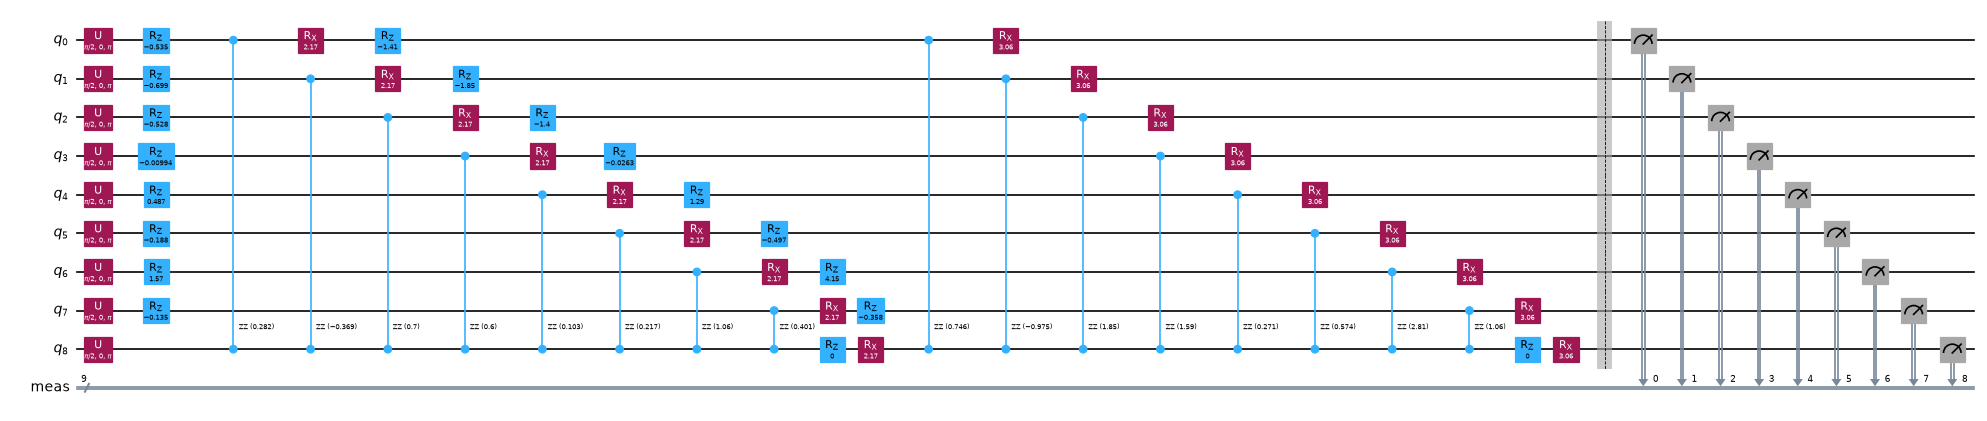

qubits: 9 (8 hidden spins + 1 output spin) | depth: 22 (high-level), 54 after transpiling to rz/rx/h/cx
gate counts: {'rz': 18, 'rx': 18, 'rzz': 16, 'u': 9} | CX count after transpile: 32
circuit parameters: 4 (= 2 p, p=2: beta_1..beta_p, gamma_1..gamma_p, re-tuned each epoch) | classical Ising parameters of the Q-WAN (J1, J2, bh, bo): 145


In [22]:
# ---- the circuit that is actually executed (free phase of sample 0), drawn from the Qiskit QAOAAnsatz object
from qiskit import transpile
circ = bound.decompose(reps=2)
from IPython.display import display
display(circ.measure_all(inplace=False).draw("mpl", fold=60, scale=0.6))      # measurement of every qubit in the Z basis is part of the executed circuit
tc = transpile(bound, basis_gates=["rz", "rx", "h", "cx"], optimization_level=0)
n_classical = K_IN * QAOA_HIDDEN + QAOA_HIDDEN + QAOA_HIDDEN + 1
print(f"qubits: {circ.num_qubits} ({QAOA_HIDDEN} hidden spins + 1 output spin) | depth: {circ.depth()} (high-level), {tc.depth()} after transpiling to rz/rx/h/cx")
print(f"gate counts: {dict(circ.count_ops())} | CX count after transpile: {tc.count_ops().get('cx', 0)}")
print(f"circuit parameters: {ans.num_parameters} (= 2 p, p={wq.p}: beta_1..beta_p, gamma_1..gamma_p, re-tuned each epoch) | classical Ising parameters of the Q-WAN (J1, J2, bh, bo): {n_classical}")

**Step 3: Q-Detection with the QAOA-solved Q-WAN** on the cells listed in `QAOA_RUNS`, next to an exact-solver Q-WAN with the same 8 hidden spins. This is the analogue of the paper's "Qiskit QAOA, 20 neurons" run; at 8 hidden spins the network is
even smaller, so the point is mainly to show that the gate-model path runs end to end; a single run of each variant is only a spot check, because NCR varies by tens of points between seeds (section 9).

In [23]:
# ---- Q-Detection with the QAOA-solved Q-WAN (H = 8 hidden spins) vs the exact-solver Q-WAN of the same size
QAOA_ROWS = []
for att, ratio in QAOA_RUNS:
    r = RES[(att, ratio)]; t0 = time.time()
    for name, w in (("QAOA (9 qubits, p=2, 64 shots)", QAOAQWAN(QAOA_HIDDEN, seed=SEED)), ("exact solver, same 8 hidden spins", QWAN(QAOA_HIDDEN, seed=SEED, solver="exact"))):
        t1 = time.time(); sel = run_detection(r["Xp"], r["yp"], w, EPOCHS, K_SEL, SEED)[0]
        QAOA_ROWS.append(dict(attack=att, ratio=f"{ratio:.0%}", Q_WAN=name, NCR=round(ncr(sel, r["isp"]), 1), solver_calls=w.calls, seconds=round(time.time() - t1)))
QAOA_TABLE = pd.DataFrame(QAOA_ROWS); print(QAOA_TABLE.to_string(index=False))

attack ratio                             Q_WAN  NCR  solver_calls  seconds
    LF   10%    QAOA (9 qubits, p=2, 64 shots) 74.4          1225      143
    LF   10% exact solver, same 8 hidden spins 10.0          1225       17


## 8. Simulated annealing inside the full loop

The grids use the exact solver for speed. This cell reruns one cell with the *sampling* solver (simulated annealing, 8 sweeps, 2 reads) for the same Q-WAN sizes, to show that the annealer-style solution of the same QUBO behaves
like the exact one. `solver_calls` counts QUBO solves (free + guided, per batch), the quantity the paper's time estimate multiplies by the time per call.

In [24]:
# ---- simulated annealing in the full loop vs the exact solver (same Q-WAN sizes, same pool)
att, ratio = "LF", RATIOS["LF"][0]; r = RES[(att, ratio)]; SA_ROWS = []
for h in HIDDEN_SIZES:
    for solver in ("sa", "exact"):
        t0 = time.time(); w = QWAN(h, seed=SEED, solver=solver)
        sel = run_detection(r["Xp"], r["yp"], w, EPOCHS, K_SEL, SEED)[0]
        SA_ROWS.append(dict(attack=att, ratio=f"{ratio:.0%}", hidden=h, solver=solver, NCR=round(ncr(sel, r["isp"]), 1), solver_calls=w.calls, seconds=round(time.time() - t0)))
print(pd.DataFrame(SA_ROWS).to_string(index=False))

attack ratio  hidden solver  NCR  solver_calls  seconds
    LF    5%      20     sa  4.4          1225       18
    LF    5%      20  exact  0.0          1225       16
    LF    5%     500     sa 53.3          1225      125
    LF    5%     500  exact 17.8          1225       39


## 9. Hidden-layer size and repeat seeds

**Size = qubits.** The paper's central scaling claim is that the number of hidden neurons (= qubits) decides the selection capability. Mean NCR per attack for 20, 500 and 5000 spins:

mean NCR % per attack and Q-WAN size (qubits = hidden neurons):
           QD_H20  QD_H500  QD_H5000
attack                              
BadNets      75.6      7.4       5.0
LF            0.0     18.9       3.9
Narcissus    68.1     21.5       0.0


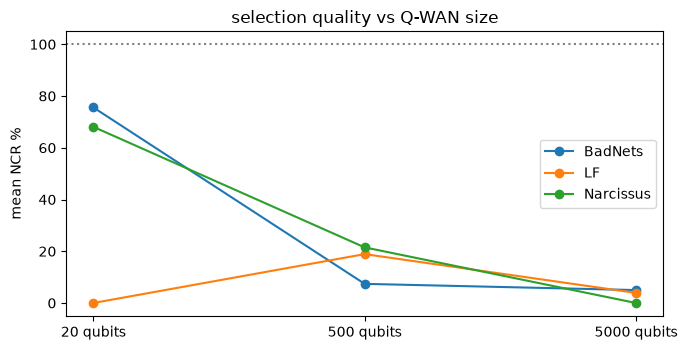

In [25]:
# ---- hidden-layer size (= number of qubits): NCR over the whole grid, averaged per attack
cols = [f"QD_H{h}" for h in HIDDEN_SIZES] + ["QD_H5000"]; cols = list(dict.fromkeys(cols))
hid = NCR_TABLE.groupby("attack")[cols].mean().round(1); print("mean NCR % per attack and Q-WAN size (qubits = hidden neurons):"); print(hid.to_string())
fig, ax = plt.subplots(figsize=(7, 3.6)); hs = [int(c[4:]) for c in cols]
for att in hid.index: ax.plot(range(len(hs)), hid.loc[att, cols], "o-", label=att)
ax.set_xticks(range(len(hs))); ax.set_xticklabels([f"{h} qubits" for h in hs]); ax.set_ylabel("mean NCR %"); ax.axhline(100, c="grey", ls=":"); ax.legend(); ax.set_title("selection quality vs Q-WAN size"); plt.tight_layout(); plt.show()

**Repeats.** One seed can mislead on cells where methods disagree, so the largest ratios of BadNets and label flipping are rerun with other seeds (new pool, new poison draw, new model initialisation, new Q-WAN couplings). The table gives mean and standard deviation of NCR over all seeds including the main one.

In [26]:
# ---- repeat the contested cells with other seeds (new pool, new poison draw, new initialisation)
REPEAT_CELLS = [("BadNets", RATIOS["BadNets"][-1]), ("LF", RATIOS["LF"][-1])]
REPEAT_SEEDS = [SEED + 1, SEED + 2] if FAST_MODE else [SEED + 1, SEED + 2, SEED + 3]
REP = []
for att, ratio in REPEAT_CELLS:
    for sd in REPEAT_SEEDS:
        Xc, yc = make_pool(xtr_all, ytr_all, N_POOL, np.random.default_rng(sd)); dl = narcissus_trigger(Xc, yc, seed=sd) if att == "Narcissus" else None
        Xp, yp, isp = poison(att, ratio, Xc, yc, np.random.default_rng(sd + 11), dl)
        res = run_methods(Xp, yp, isp, sd, which=["DCM", "LossScan", "MetaSift", f"QD_H{MAIN_H}", "QD_H5000"])
        REP.append(dict(attack=att, ratio=f"{ratio:.0%}", seed=sd, **{m: round(ncr(v[0], isp), 1) for m, v in res.items()}))
        print(REP[-1], flush=True)
REPDF = pd.DataFrame(REP)
# include the main-seed run so that the summary has all seeds
for (att, ratio) in REPEAT_CELLS:
    r = RES[(att, ratio)]; REPDF = pd.concat([REPDF, pd.DataFrame([dict(attack=att, ratio=f"{ratio:.0%}", seed=SEED, **{m: round(ncr(r["sel"][m], r["isp"]), 1) for m in ["DCM", "LossScan", "MetaSift", f"QD_H{MAIN_H}", "QD_H5000"]})])])
print(REPDF.groupby(["attack", "ratio"])[["DCM", "LossScan", "MetaSift", f"QD_H{MAIN_H}", "QD_H5000"]].agg(["mean", "std"]).round(1).to_string())

{'attack': 'BadNets', 'ratio': '30%', 'seed': 43, 'DCM': 162.6, 'LossScan': 333.3, 'MetaSift': 135.2, 'QD_H500': 148.1, 'QD_H5000': 4.8}


{'attack': 'BadNets', 'ratio': '30%', 'seed': 44, 'DCM': 137.8, 'LossScan': 333.3, 'MetaSift': 131.1, 'QD_H500': 4.1, 'QD_H5000': 0.4}


{'attack': 'LF', 'ratio': '10%', 'seed': 43, 'DCM': 48.9, 'LossScan': 3.3, 'MetaSift': 144.4, 'QD_H500': 10.0, 'QD_H5000': 20.0}


{'attack': 'LF', 'ratio': '10%', 'seed': 44, 'DCM': 44.4, 'LossScan': 1.1, 'MetaSift': 118.9, 'QD_H500': 14.4, 'QD_H5000': 16.7}


                 DCM       LossScan      MetaSift       QD_H500       QD_H5000     
                mean   std     mean  std     mean   std    mean   std     mean  std
attack  ratio                                                                      
BadNets 30%    164.0  26.9    333.3  0.0    134.8   3.5    52.0  83.3      2.1  2.4
LF      10%     47.8   3.0      2.2  1.1    135.9  14.7    14.8   5.0     14.1  7.5


## 10. The speed estimate of Section 4.4

The paper's quantum speed-up is not measured but *estimated*: it multiplies the number of Q-WAN QUBO calls by a time per call, divides the quantum part by 1000 (the ratio between simulated and real Ising-machine time they measured on a 550-qubit device) and compares
with the 3 minutes of Meta-Sift on a GPU. (a) re-does that arithmetic, (b) shows what the stand-in solvers cost here.

In [27]:
# ---- Section 4.4 of the paper: speed estimate, (a) the arithmetic as published, (b) our own measured solver times
epochs_bs44, calls = 892, 3568; sec_per_call = 4.5 / 4; sim_minutes = calls * sec_per_call / 60
print("(a) arithmetic of the paper's estimate")
print(f"    3,568 calls x {sec_per_call:.3f} s = {sim_minutes:.1f} min   (paper: 66.9 min)  -> consistent: {abs(sim_minutes - 66.9) < 0.1}")
total_classical = 69 - 66.9; print(f"    classical part = 69 - 66.9 = {total_classical:.1f} min   (paper: 2.1 min)")
cim = total_classical + 66.9 / 1000; print(f"    with a 10^3 faster Ising machine: {total_classical:.1f} + {66.9 / 1000:.4f} = {cim:.2f} min   (paper: 2.17 min)")
print(f"    speed-up vs Meta-Sift (3 min): {(3 - cim) / 3:.1%}   (paper: 'over 20 %')  -> consistent: {(3 - cim) / 3 > 0.2}")
print("    caveat: the 10^3 factor is the simulated-vs-real ratio measured by the authors on a 550-qubit CIM; it is not measured here, and 3 min for Meta-Sift is on a GPU.")
print("(b) measured here (one batch of %d real losses)" % BATCH)
Lb = Lq[batch]; rows = []
for nm, w in (("exact Boltzmann, H=500", QWAN(500, solver="exact")), ("simulated annealing, H=500 (8 sweeps, 2 reads)", QWAN(500, solver="sa")), ("exact Boltzmann, H=5000", QWAN(5000, solver="exact")),
              ("simulated annealing, H=5000", QWAN(5000, solver="sa")), ("QAOA statevector, 9 qubits, 64 shots", wq)):
    t0 = time.time()
    for _ in range(3): w.train_step(Lb, torch.where(Lb > Lb.median(), -1.0, 1.0))
    rows.append(dict(solver=nm, ms_per_train_step=round(1000 * (time.time() - t0) / 3)))
print(pd.DataFrame(rows).to_string(index=False)); print("(CPU timings on a shared machine; they only show the relative cost of the stand-ins, not the speed of real quantum hardware.)")

(a) arithmetic of the paper's estimate
    3,568 calls x 1.125 s = 66.9 min   (paper: 66.9 min)  -> consistent: True
    classical part = 69 - 66.9 = 2.1 min   (paper: 2.1 min)
    with a 10^3 faster Ising machine: 2.1 + 0.0669 = 2.17 min   (paper: 2.17 min)
    speed-up vs Meta-Sift (3 min): 27.8%   (paper: 'over 20 %')  -> consistent: True
    caveat: the 10^3 factor is the simulated-vs-real ratio measured by the authors on a 550-qubit CIM; it is not measured here, and 3 min for Meta-Sift is on a GPU.
(b) measured here (one batch of 179 real losses)


                                        solver  ms_per_train_step
                        exact Boltzmann, H=500                 38
simulated annealing, H=500 (8 sweeps, 2 reads)                143
                       exact Boltzmann, H=5000                163
                   simulated annealing, H=5000                941
          QAOA statevector, 9 qubits, 64 shots                201
(CPU timings on a shared machine; they only show the relative cost of the stand-ins, not the speed of real quantum hardware.)


## 11. The paper's numbers next to this notebook's

The verdicts are computed from the tables above. "Reproduced" needs the notebook value inside the stated tolerance; the tolerance for NCR cells is described in section 6.2. A claim that depends on hardware or on the size of the original experiments is marked as not checkable.

In [28]:
# ---- claim-by-claim verdicts
def share(df, method, ok): d = df[df.method == method]; return (ok(d).mean() if len(d) else np.nan, len(d))
q500 = CMP[CMP.method == f"QD_H{MAIN_H}"]; V = []
lf = q500[q500.attack == "LF"]
V.append(("C1a Q-Det 500 qubits: NCR = 0 % for label flipping at every ratio", "0 % (3..30 %)", f"{', '.join(f'{r}%: {v:.0f}' for r, v in zip(lf.ratio, lf.notebook_NCR))}",
          "reproduced" if (lf.notebook_NCR <= 15).all() else ("partially" if (lf.notebook_NCR <= 25).mean() >= 0.5 else "not reached here")))
bk = q500[q500.attack != "LF"]; easy = bk[~(((bk.attack == "BadNets") & (bk.ratio >= 10)) | ((bk.attack == "Narcissus") & (bk.ratio >= 30)))]; hard = bk[(((bk.attack == "BadNets") & (bk.ratio >= 10)) | ((bk.attack == "Narcissus") & (bk.ratio >= 30)))]
V.append(("C1b Q-Det 500 qubits: ~0 % on backdoors with low/medium ratios", "0 %", f"{len(easy)} cells, mean NCR {easy.notebook_NCR.mean():.0f} %" if len(easy) else "no such cell", "reproduced" if len(easy) and (easy.notebook_NCR <= 15).all() else ("partially" if len(easy) and (easy.notebook_NCR <= 25).mean() >= 0.5 else ("cannot be checked" if not len(easy) else "not reached here"))))
V.append(("C1c Q-Det 500 qubits FAILS on BadNets >= 10 % / Narcissus 30 %", "110..366 %", (f"{len(hard)} cells, NCR " + ", ".join(f"{a} {r}%: {v:.0f}" for a, r, v in zip(hard.attack, hard.ratio, hard.notebook_NCR))) if len(hard) else "no such cell",
          "cannot be checked" if not len(hard) else ("reproduced" if (hard.notebook_NCR > 75).all() else "not reached here (our 500-neuron network does not fail there)")))
q5k = CMP[CMP.method == "QD_H5000"]
V.append(("C2 Q-Det with 5000 qubits: NCR = 0 % everywhere", "0 %", f"mean NCR {q5k.notebook_NCR.mean():.1f} %, worst {q5k.notebook_NCR.max():.0f} %" if len(q5k) else "not run",
          "cannot be checked" if not len(q5k) else ("reproduced" if (q5k.notebook_NCR <= 15).all() else ("partially" if (q5k.notebook_NCR <= 25).mean() >= 0.5 else "not reached here"))))
h20 = NCR_TABLE["QD_H20"]; h500 = NCR_TABLE[f"QD_H{MAIN_H}"]
V.append(("C3 20 hidden neurons (20 qubits) are too few: training fails", "NCR 929 % (QAOA)", f"mean NCR {h20.mean():.0f} % vs {h500.mean():.0f} % for 500 neurons; worse than random in {int((h20 > 100).sum())}/{len(h20)} cells",
          "reproduced" if h20.mean() > h500.mean() + 25 and (h20 > 75).mean() >= 0.5 else ("partially" if h20.mean() > h500.mean() else "not reached here (no gap between 20 and 500 neurons)")))
for m, label in (("DCM", "C4a DCM"), ("LossScan", "C4b LossScan"), ("AutoEncoder", "C4c Autoencoder outlier"), ("MetaSift", "C4d Meta-Sift (SOTA) ~0 % everywhere")):
    a, n = share(CMP, m, lambda d: d.agree)
    V.append((f"{label}: per-cell agreement with Table 1", "see Table 1", f"{a:.0%} of {n} cells agree (category or +-15 points)", "reproduced" if a >= 0.8 else ("partially" if a >= 0.5 else "not reached here")))
f1 = FIG1.pivot(index="ratio", columns="method", values="acc"); d = (f1[f"QD_H{MAIN_H}"] - f1["MetaSift"])
V.append(("C5 model trained on Q-Det subset >= model trained on Meta-Sift subset (overall accuracy)", "higher by about 1-3 points at 20/30 %", "difference QD-500 minus Meta-Sift-style: " + ", ".join(f"{i}%: {x:+.3f}" for i, x in d.items()),
          "reproduced" if (d >= -0.02).all() else ("partially" if (d >= -0.02).any() else "not reached here")))
V.append(("C6 Section 4.4 time-estimate arithmetic (66.9 min, 2.17 min, > 20 % speed-up)", "66.9 / 2.17 min / > 20 %", f"{sim_minutes:.1f} / {cim:.2f} min / {(3 - cim) / 3:.1%}", "reproduced (arithmetic only; hardware speed not measurable here)"))
VERDICTS = pd.DataFrame(V, columns=["claim", "paper", "this notebook", "verdict"]); pd.set_option("display.max_colwidth", 120); print(VERDICTS.to_string(index=False))

                                                                                   claim                                 paper                                                         this notebook                                                          verdict
                       C1a Q-Det 500 qubits: NCR = 0 % for label flipping at every ratio                         0 % (3..30 %)                                                       5%: 18, 10%: 20                                                        partially
                          C1b Q-Det 500 qubits: ~0 % on backdoors with low/medium ratios                                   0 %                                                2 cells, mean NCR 27 %                                                        partially
                          C1c Q-Det 500 qubits FAILS on BadNets >= 10 % / Narcissus 30 %                            110..366 %                         2 cells, NCR BadNets 30%: 4, Narcissus 30%: 0    not reached he

## 12. Reading the paper critically

(The numbers quoted below are from the executed run stored in this file: FAST_MODE, seed 42. If you change the configuration, re-read them against your own tables.)

**What this run shows.**
- With the exact QUBO solver, the 500-neuron Q-WAN reaches NCR between 0 % and 43 % on the six cells (label flipping 18 and 20 %, BadNets 11 and 4 %, Narcissus 43 and 0 %), the 5000-neuron Q-WAN between 0 % and 9 %,
  and the 20-neuron Q-WAN is fine for label flipping (0 %) but poor on the backdoors (50 to 89 %). So the *qualitative* story of the paper (a wider Q-WAN selects cleaner subsets, a 20-spin network is too small, backdoors and label flipping can be handled) is visible, at a scale
  where the clean-data baselines of the paper are not reproduced either (see below). The paper's *specific* failure cells (500 qubits on BadNets 10 / 30 % and Narcissus 30 %) did **not** fail here.
- The result of a single run is fragile. The 500-neuron Q-WAN on BadNets 30 % gave NCR 4 % with the main seed, 148 % with seed 43 and 4 % with seed 44 (section 9); the 5000-neuron network was stable (2 +- 2 %). Single-seed tables such as the paper's Table 1 (no seeds or error bars are reported) cannot show this.

**What is not established.**
- **The Meta-Sift column is not Meta-Sift.** The "MetaSift" method here is a simplified stand-in (same hypergradient, one free weight per sample) and it does **not** reproduce the paper's 0 % (NCR 65 to 144 %). The paper's claim "Q-Detection is comparable to the state of the art" therefore cannot be checked with this baseline, and the C4d / C5 verdicts say something about the stand-in, not about Meta-Sift.
- **What the weight network actually sees.** The Q-WAN input is one number per sample, its loss. A network that sees only the loss can at best learn a threshold on it. That Q-Detection still works on backdoors is therefore a property of the *loop* (the domain model is trained with the weights, so it
  is kept from learning the trigger and the poisoned samples keep a high loss), not of any quantum part. In this run the *same* network shape trained by back-propagation instead of equilibrium propagation on the QUBO ("ClassicalWAN_H500") failed on the backdoors (NCR 176 to 387 %) while the QUBO-trained one did not. This was observed on one seed and not investigated: the effective learning speed or the saturation of the output probability are candidate explanations, a genuine advantage of the QUBO formulation is not.
- **Nothing here is evidence of a quantum advantage.** Training is an Ising-network problem solved with classical simulators, as in the paper. The paper's "over 20 % speed-up" is arithmetic on a measured *simulation* time and an assumed 1000x hardware factor, and the classical part (2.1 min of the 2.17 min total) is not accelerated.
  The notebook re-checks the arithmetic (it is consistent); it cannot check the hardware factor.
- **Hyper-parameters were chosen with the answer in hand.** The virtual step size and the 1/H scaling of the Q-WAN learning rate were picked on a development seed by looking at NCR, which needs the poison mask. A real defender has no such mask, and the paper does not say how its settings were chosen. With the other candidate step size (0.5) the Q-WAN was much worse on label flipping in development runs, so the outcome depends on this choice.
- **The free parameters decide the outcome.** The paper does not say how the targets for the output spin are constructed, which trigger sizes or Narcissus settings were used, how ties among equal weights are broken, or how many seeds were run. Each of these had to be invented here.
- **NCR is a ratio of rare events.** For Narcissus the poisoned images are 0.5 % (31 images) and 1.5 % (93 images) of the pool, so a random subset of 900 contains about 5 and 14 of them, and NCR moves in steps of about 20 and 7 points per image. The paper reports exact 0.00 % in most cells without the number of poisoned images.
- **Fig. 1 analogue.** At 5 % label flipping a *random* subset is already as good as the oracle, and the defences that pick "easy" samples (DCM, LossScan, autoencoder) lose accuracy through class imbalance in the subset even when their NCR is good. A clean subset is not automatically a good training set.
- **Hardware-size claims.** "More qubits give better selection" is tested here only through the *width of a classical Ising network*; whether a real 5000-qubit annealer would reach the same states (embedding, noise, chain breaks) is touched neither here nor by the paper's simulations.
- **Gate-model part.** The QAOA solver finds the exact ground state of the 9-qubit QUBO in most shots and runs end to end inside the loop; its NCR in the loop (74 %) is worse than the exact solver's (10 %) at the same size on one seed, which is within the seed-to-seed spread seen above. The paper's QAOA experiment used 20 qubits and failed (929 %); nothing here says whether larger QAOA circuits would work.

## 13. Exercises

1. **Better targets.** Replace the Otsu split of the hypergradient by a split at a fixed quantile (say the lowest 30 %), or change `ETA_VIRTUAL` (0.1 -> 0.5). How do NCR and its seed-to-seed spread change on BadNets 30 % and label flipping 10 %?
2. **A richer Q-WAN input.** Feed the Q-WAN the loss *and* a second feature (the distance of the sample's feature vector to its class mean, as a second thermometer code). Does the 500-neuron network now use its width?
3. **Annealing temperature.** Change `BETA_EXACT` (0.5, 1, 2, 4, 8) and `BETA_HIGH`. How sensitive is NCR? Which end is closer to a real annealer's thermal noise?
4. **QAOA depth.** Set `QAOA_P` to 1 and 3 and compare the share of reads that reach the exact ground state in the quality cell. What does the circuit drawing and the CX count do?
5. **Different clean-label attack.** Make the Narcissus patch smaller (`size=3`) or weaker (`eps=24`). Which defences still see it? Does the attack still succeed (attack success rate in the Fig. 1 helper `evaluate`)?